# Clasificación de flores con Redes Neuronales Convolucionales
### Proyecto final · Deep Learning · Universidad de La Sabana

**Integrantes:** _(completar)_

**Problema:** identificar automáticamente la especie de una flor a partir de una fotografía, entre **102 especies**, usando el dataset **Oxford 102 Category Flower Dataset**.

**Contenido del notebook**

1. Selección y justificación de la base de datos
2. Configuración del entorno
3. Carga de datos y control de calidad
4. Análisis exploratorio (EDA)
5. Preprocesamiento, partición de datos y aumento de datos
6. Modelo A: CNN propia desde cero (residual + atención Squeeze-and-Excitation)
7. Experimentación con hiperparámetros
8. Modelo B: transfer learning con ResNet preentrenada en ImageNet
9. Evaluación y análisis de resultados
10. Explicabilidad (Grad-CAM), robustez y pruebas con fotos del mundo real
11. Consumo energético, exportación del modelo y conclusiones


## 1. Selección y justificación de la base de datos

### 1.1 ¿Por qué clasificar flores?
- **Biodiversidad y ciencia ciudadana:** aplicaciones como Pl@ntNet o iNaturalist permiten que cualquier persona identifique especies con el celular y genere datos útiles para la conservación.
- **Floricultura:** Colombia es uno de los mayores exportadores de flores de corte del mundo. Un clasificador automático sirve para control de calidad, para clasificar variedades en poscosecha y para hacer inventario. _(Confirmen la cifra exacta de exportaciones con una fuente oficial, por ejemplo Asocolflores, antes de ponerla en la presentación.)_
- **Educación y turismo:** guías de jardines botánicos y apps educativas.

### 1.2 Bases de datos consideradas (análisis comparativo)

| Base de datos | Clases | Imágenes | Ventajas | Desventajas |
|---|---|---|---|---|
| **Oxford 102 Flowers** (Nilsback & Zisserman, 2008) | 102 | 8.189 | Dataset académico citable, integrado en `torchvision`, clases muy parecidas entre sí (reto fino), desbalance real (40–258 imágenes por clase), incluye máscaras de segmentación | Pocas imágenes por clase, especies del Reino Unido |
| Flowers Recognition (Kaggle, alxmamaev) | 5 | 4.242 | Fácil de usar, clases balanceadas (~800 por clase) | Solo 5 clases (problema demasiado fácil), baja resolución (~320×240), licencia desconocida, imágenes extraídas de buscadores |
| TF Flowers (TensorFlow Datasets) | 5 | ~3.670 | Muy usado en tutoriales | Mismo problema: solo 5 clases muy distintas |
| iNaturalist 2021 | ~10.000 especies (todas, no solo flores) | ~2,7 M | Enorme y realista | Demasiado grande para los recursos del curso (Colab) |

**Decisión:** escogemos **Oxford 102** porque es un problema de *clasificación de grano fino* (fine-grained). Exige que la red aprenda detalles de forma, textura y color, tiene un desbalance de clases real que debemos manejar, y su tamaño permite entrenar con los recursos del curso. Además está validado académicamente, lo que facilita comparar nuestros resultados con la literatura.

**Referencia:** Nilsback, M-E. y Zisserman, A. *Automated flower classification over a large number of classes.* ICVGIP, 2008. https://www.robots.ox.ac.uk/~vgg/data/flowers/102/

## 2. Configuración del entorno
Todas las decisiones configurables están en la celda de abajo. Si quieren hacer una prueba rápida de que todo corre, pongan `QUICK_RUN = True`.

In [1]:
# Librería opcional (solo imprime el resumen de la arquitectura). Si falla, el notebook sigue funcionando.
%pip install -q torchinfo

In [2]:
import os, sys, time, json, random, hashlib, copy, math
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter, ImageEnhance
from scipy.io import loadmat

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision import transforms, models
from torchvision.datasets import Flowers102

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, top_k_accuracy_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             log_loss)
from sklearn.preprocessing import label_binarize
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# ----------------------------- CONFIGURACIÓN -----------------------------
SEED = 42
QUICK_RUN = False          # True = pocas épocas, solo para verificar que todo corre

EN_COLAB = "google.colab" in sys.modules
BASE_DIR = Path("/content") if EN_COLAB else Path.cwd()   # en VS Code: la carpeta donde está el notebook
DATA_ROOT = BASE_DIR / "data"                             # aquí se descarga el dataset (~330 MB)

# ¿Ya tienen las imágenes descargadas? Pongan True y la ruta de la carpeta que contiene
# jpg/, imagelabels.mat y setid.mat (por ejemplo r"C:\Users\tomas\Downloads\flowers-102").
# Si solo tienen la carpeta jpg/ sin los .mat, dejen False y el notebook descarga todo.
USAR_MIS_IMAGENES = False
MIS_IMAGENES_DIR = r"C:\ruta\a\flowers-102"

CHECKPOINT_DIR = BASE_DIR / "checkpoints"
BATCH_SIZE = 64
NUM_WORKERS = 0 if os.name == "nt" else 2   # en Windows los DataLoader con varios procesos fallan en notebooks
VAL_FRAC, TEST_FRAC = 0.15, 0.15
PATIENCE = 8                                # early stopping
PRETRAINED = True                           # usar pesos de ImageNet en el Modelo B
RUN_TSNE = True                             # visualización t-SNE en el EDA
RUN_ABLATION = True                         # ablación del Modelo A (~25 min extra en T4; pongan False si no hay tiempo)
ROBUST_AUG = True                           # aumento con desenfoque y ruido (decisión tomada tras la corrida 1, ver 5.3)

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"   # precisión mixta: entrena ~2x más rápido en GPU

if device == "cuda":         # configuración completa
    IMG_SIZE, RESIZE_SHORT_SIDE = 224, 256
    TL_ARCH = "resnet50"
    EPOCHS_SCRATCH, EPOCHS_TL_HEAD, EPOCHS_TL_FT = 50, 5, 12
else:                        # configuración liviana para CPU
    IMG_SIZE, RESIZE_SHORT_SIDE = 160, 182
    TL_ARCH = "resnet18"
    EPOCHS_SCRATCH, EPOCHS_TL_HEAD, EPOCHS_TL_FT = 20, 3, 8
    BATCH_SIZE = 32

if QUICK_RUN:
    EPOCHS_SCRATCH, EPOCHS_TL_HEAD, EPOCHS_TL_FT, PATIENCE = 2, 1, 1, 2
# --------------------------------------------------------------------------

TL_NAME = {"resnet50": "ResNet-50", "resnet18": "ResNet-18"}[TL_ARCH]
RESIZED_DIR = DATA_ROOT / f"flowers-102-{RESIZE_SHORT_SIDE}"   # copia redimensionada (más rápida)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print("Entorno:", "Google Colab" if EN_COLAB else "local (VS Code / Jupyter)", "| carpeta base:", BASE_DIR)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| dispositivo:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Sin GPU: se usa la configuración liviana (160 px, ResNet-18, menos épocas). "
          "Si tienen GPU NVIDIA, revisen que instalaron PyTorch con CUDA.")
print(f"Imagen {IMG_SIZE}px | Modelo B: {TL_NAME} | épocas A={EPOCHS_SCRATCH}, B={EPOCHS_TL_HEAD}+{EPOCHS_TL_FT}")

Entorno: Google Colab | carpeta base: /content
PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130 | dispositivo: cuda
GPU: Tesla T4
Imagen 224px | Modelo B: ResNet-50 | épocas A=50, B=5+12


## 3. Carga de datos y control de calidad

`torchvision` descarga automáticamente las imágenes (`jpg/`), las etiquetas (`imagelabels.mat`) y la partición oficial (`setid.mat`).
Si ya tienen las imágenes, pongan `USAR_MIS_IMAGENES = True` y la ruta en `MIS_IMAGENES_DIR`. La carpeta debe contener `jpg/`, `imagelabels.mat` y `setid.mat`.

In [3]:
if USAR_MIS_IMAGENES:
    if EN_COLAB and MIS_IMAGENES_DIR.startswith("/content/drive"):
        from google.colab import drive
        drive.mount("/content/drive")
    FLOWERS_DIR = Path(MIS_IMAGENES_DIR)
else:
    Flowers102(DATA_ROOT, split="train", download=True)   # descarga todo una sola vez (~330 MB)
    FLOWERS_DIR = DATA_ROOT / "flowers-102"

IMG_DIR = FLOWERS_DIR / "jpg"
print("Carpeta de imágenes:", IMG_DIR, "| archivos:", len(os.listdir(IMG_DIR)))

Carpeta de imágenes: /content/data/flowers-102/jpg | archivos: 8189


In [4]:
# Nombres de las 102 especies (índice 0 = etiqueta 1 del dataset original)
CLASS_NAMES = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea", "english marigold",
    "tiger lily", "moon orchid", "bird of paradise", "monkshood", "globe thistle", "snapdragon",
    "colt's foot", "king protea", "spear thistle", "yellow iris", "globe-flower", "purple coneflower",
    "peruvian lily", "balloon flower", "giant white arum lily", "fire lily", "pincushion flower",
    "fritillary", "red ginger", "grape hyacinth", "corn poppy", "prince of wales feathers",
    "stemless gentian", "artichoke", "sweet william", "carnation", "garden phlox", "love in the mist",
    "mexican aster", "alpine sea holly", "ruby-lipped cattleya", "cape flower", "great masterwort",
    "siam tulip", "lenten rose", "barbeton daisy", "daffodil", "sword lily", "poinsettia",
    "bolero deep blue", "wallflower", "marigold", "buttercup", "oxeye daisy", "common dandelion",
    "petunia", "wild pansy", "primula", "sunflower", "pelargonium", "bishop of llandaff", "gaura",
    "geranium", "orange dahlia", "pink-yellow dahlia", "cautleya spicata", "japanese anemone",
    "black-eyed susan", "silverbush", "californian poppy", "osteospermum", "spring crocus",
    "bearded iris", "windflower", "tree poppy", "gazania", "azalea", "water lily", "rose",
    "thorn apple", "morning glory", "passion flower", "lotus", "toad lily", "anthurium",
    "frangipani", "clematis", "hibiscus", "columbine", "desert-rose", "tree mallow", "magnolia",
    "cyclamen", "watercress", "canna lily", "hippeastrum", "bee balm", "ball moss", "foxglove",
    "bougainvillea", "camellia", "mallow", "mexican petunia", "bromelia", "blanket flower",
    "trumpet creeper", "blackberry lily"]
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == 102

labels = loadmat(FLOWERS_DIR / "imagelabels.mat")["labels"][0] - 1     # 0..101
setid = loadmat(FLOWERS_DIR / "setid.mat")
official = {}
for key, name in [("trnid", "train"), ("valid", "val"), ("tstid", "test")]:
    for i in setid[key][0]:
        official[int(i)] = name

df = pd.DataFrame({
    "image_id": np.arange(1, len(labels) + 1),
    "filename": [f"image_{i:05d}.jpg" for i in range(1, len(labels) + 1)],
    "label": labels,
})
df["class_name"] = df["label"].map(lambda l: CLASS_NAMES[l])
df["official_split"] = df["image_id"].map(official)
print("Total de imágenes con etiqueta:", len(df))
print(df["official_split"].value_counts())
df.head()

Total de imágenes con etiqueta: 8189
official_split
test     6149
val      1020
train    1020
Name: count, dtype: int64


,image_id,filename,label,class_name,official_split
0,1,image_00001.jpg,76,passion flower,test
1,2,image_00002.jpg,76,passion flower,test
2,3,image_00003.jpg,76,passion flower,test
3,4,image_00004.jpg,76,passion flower,test
4,5,image_00005.jpg,76,passion flower,test


### 3.1 Control de calidad: archivos faltantes, imágenes corruptas y duplicados
Antes de entrenar verificamos que:
- todas las imágenes etiquetadas existen (deben ser **8.189**);
- ninguna está corrupta;
- no hay imágenes **duplicadas**. Un duplicado repartido entre entrenamiento y prueba inflaría las métricas (*data leakage*).

In [5]:
existing = set(os.listdir(IMG_DIR))
missing = [f for f in df["filename"] if f not in existing]
print(f"Imágenes esperadas: {len(df)} | encontradas: {len(df) - len(missing)} | faltantes: {len(missing)}")

def inspect_image(fname):
    path = IMG_DIR / fname
    try:
        with Image.open(path) as im:
            w, h = im.size
            mode = im.mode
            im.verify()                      # detecta archivos corruptos
        md5 = hashlib.md5(path.read_bytes()).hexdigest()
        return fname, w, h, mode, md5, True
    except Exception:
        return fname, None, None, None, None, False

with ThreadPoolExecutor(8) as ex:
    info = list(ex.map(inspect_image, df["filename"]))
info = pd.DataFrame(info, columns=["filename", "width", "height", "mode", "md5", "ok"])
df = df.merge(info, on="filename")

print("Imágenes corruptas:", (~df["ok"]).sum())
print("Modos de color:", df["mode"].value_counts().to_dict())
dups = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Imágenes duplicadas exactas:", len(dups))
if len(dups):
    display(dups[["filename", "class_name", "md5"]].head(20))

# Nos quedamos con una sola copia de cada imagen y descartamos corruptas
df = df[df["ok"]].drop_duplicates("md5").reset_index(drop=True)
print("Imágenes utilizables:", len(df))

Imágenes esperadas: 8189 | encontradas: 8189 | faltantes: 0
Imágenes corruptas: 0
Modos de color: {'RGB': 8189}
Imágenes duplicadas exactas: 8


,filename,class_name,md5
7322,image_07323.jpg,foxglove,28dc3ced5bcea79dff2d520c9faff934
7327,image_07328.jpg,foxglove,28dc3ced5bcea79dff2d520c9faff934
7306,image_07307.jpg,foxglove,454bab361c983cc4d681dae9f5d42be0
7308,image_07309.jpg,foxglove,454bab361c983cc4d681dae9f5d42be0
7884,image_07885.jpg,bromelia,8a645f3ded910a5349a6e7340445a673
7885,image_07886.jpg,bromelia,8a645f3ded910a5349a6e7340445a673
8066,image_08067.jpg,carnation,d5de43837c54fac145cb6d22fea210d0
8076,image_08077.jpg,carnation,d5de43837c54fac145cb6d22fea210d0


Imágenes utilizables: 8185


### 3.2 Preprocesamiento offline: redimensionar una sola vez
Las fotos originales miden ~500–1000 px. Decodificarlas en cada época es lento, así que guardamos una copia con el lado corto a 256 px (se conserva la proporción). Así el entrenamiento en Colab es varias veces más rápido sin perder información relevante para una entrada de 224×224.

In [6]:
os.makedirs(RESIZED_DIR, exist_ok=True)

def resize_one(fname):
    out = Path(RESIZED_DIR) / fname
    if out.exists():
        return
    with Image.open(IMG_DIR / fname) as im:
        im = im.convert("RGB")
        w, h = im.size
        s = RESIZE_SHORT_SIDE / min(w, h)
        im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
        im.save(out, quality=95)

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    list(ex.map(resize_one, df["filename"]))
print(f"Redimensionadas {len(df)} imágenes en {time.time() - t0:.1f} s -> {RESIZED_DIR}")

Redimensionadas 8185 imágenes en 0.7 s -> /content/data/flowers-102-256


## 4. Análisis exploratorio de datos (EDA)
### 4.1 Distribución de clases

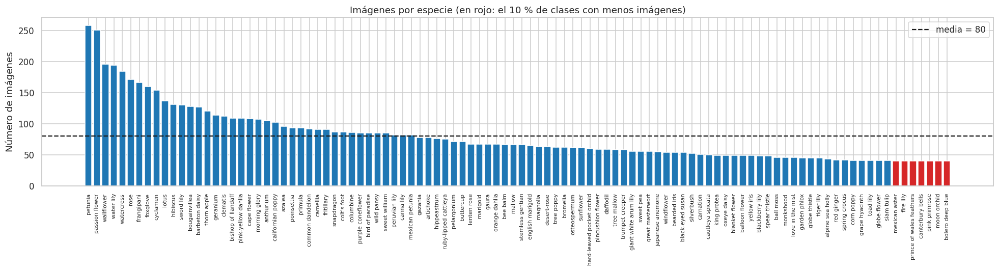

,valor
clases,102.00
imágenes,8185.00
mínimo,40.00
máximo,258.00
media,80.20
mediana,66.00
desv. estándar,44.30
ratio de desbalance (máx/mín),6.45


Clases con más imágenes:
 class_name
petunia           258
passion flower    251
wallflower        196
water lily        194
watercress        184

Clases con menos imágenes:
 class_name
prince of wales feathers    40
canterbury bells            40
pink primrose               40
moon orchid                 40
bolero deep blue            40


In [7]:
counts = df["class_name"].value_counts()
fig, ax = plt.subplots(figsize=(18, 5))
colors = ["#d62728" if c < counts.quantile(0.1) else "#1f77b4" for c in counts.values]
ax.bar(range(len(counts)), counts.values, color=colors)
ax.axhline(counts.mean(), color="k", ls="--", label=f"media = {counts.mean():.0f}")
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=7)
ax.set_ylabel("Número de imágenes")
ax.set_title("Imágenes por especie (en rojo: el 10 % de clases con menos imágenes)")
ax.legend(); plt.tight_layout(); plt.show()

stats = pd.Series({
    "clases": counts.size, "imágenes": counts.sum(), "mínimo": counts.min(), "máximo": counts.max(),
    "media": round(counts.mean(), 1), "mediana": counts.median(), "desv. estándar": round(counts.std(), 1),
    "ratio de desbalance (máx/mín)": round(counts.max() / counts.min(), 2)})
display(stats.to_frame("valor"))
print("Clases con más imágenes:\n", counts.head(5).to_string())
print("\nClases con menos imágenes:\n", counts.tail(5).to_string())

**Observaciones:**
- **Control de calidad:** las 8.189 imágenes están completas y ninguna está corrupta, pero encontramos **4 pares de imágenes duplicadas exactas** (2 en *foxglove*, 1 en *bromelia* y 1 en *carnation*). Eliminamos una copia de cada par (quedan 8.185). Si no lo hiciéramos, una misma foto podría quedar en entrenamiento y en prueba e inflar las métricas.
- **Desbalance:** las clases van de **40** imágenes (*pink primrose*, *moon orchid*, *canterbury bells*...) a **258** (*petunia*). Es un **ratio de 6,45**, con media de 80 y mediana de 66 imágenes por clase. La mediana es menor que la media porque unas pocas clases muy grandes (*petunia*, *passion flower*, *wallflower*) jalan el promedio hacia arriba.
- **Consecuencia:** sin corrección, el modelo tendería a favorecer las clases frecuentes. Por eso en la sección 5 usamos **muestreo balanceado** y reportamos métricas *macro* (F1 macro, accuracy balanceada), que dan el mismo peso a cada especie. En la sección 9.2 comprobamos si funcionó.

### 4.2 Tamaño y proporción de las imágenes

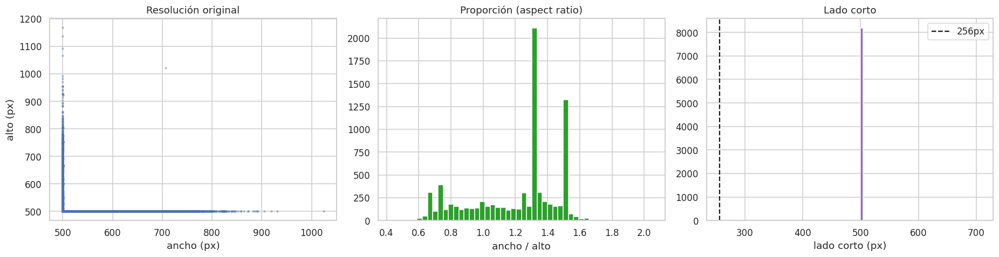

        width  height
count  8185.0  8185.0
mean    630.0   534.0
std      96.0    75.0
min     500.0   500.0
25%     501.0   500.0
50%     667.0   500.0
75%     699.0   501.0
max    1024.0  1168.0
Horizontales: 75.0% | verticales: 24.1% | cuadradas: 0.9%


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(df["width"], df["height"], s=4, alpha=0.3)
axes[0].set_xlabel("ancho (px)"); axes[0].set_ylabel("alto (px)"); axes[0].set_title("Resolución original")
aspect = df["width"] / df["height"]
axes[1].hist(aspect, bins=50, color="#2ca02c")
axes[1].set_xlabel("ancho / alto"); axes[1].set_title("Proporción (aspect ratio)")
short = df[["width", "height"]].min(axis=1)
axes[2].hist(short, bins=50, color="#9467bd")
axes[2].axvline(RESIZE_SHORT_SIDE, color="k", ls="--", label=f"{RESIZE_SHORT_SIDE}px")
axes[2].set_xlabel("lado corto (px)"); axes[2].set_title("Lado corto"); axes[2].legend()
plt.tight_layout(); plt.show()
print(df[["width", "height"]].describe().round(0))
print(f"Horizontales: {(aspect > 1).mean():.1%} | verticales: {(aspect < 1).mean():.1%} | cuadradas: {(aspect == 1).mean():.1%}")

**Observaciones:** todas las imágenes tienen el lado corto de ~500 px; el lado largo va hasta ~1.170 px. El 75 % son horizontales, el 24 % verticales y menos del 1 % cuadradas. Por eso las redimensionamos por el lado corto (conservando la proporción) y luego recortamos a 224×224, en lugar de deformarlas. Con 500 px de partida, reducir a 256 no pierde información relevante para una entrada de 224.

### 4.3 Una imagen de cada una de las 102 especies

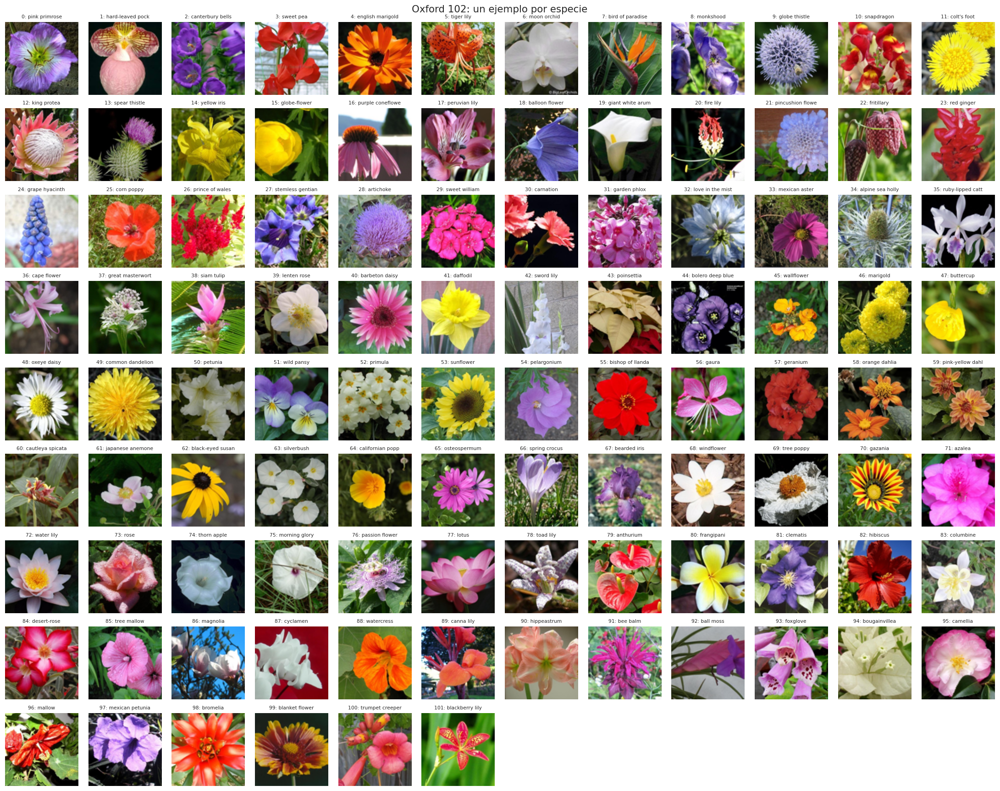

In [9]:
def load_rgb(fname, root=RESIZED_DIR):
    with Image.open(Path(root) / fname) as im:
        return im.convert("RGB")

sample = df.groupby("label").sample(1, random_state=SEED).sort_values("label")
fig, axes = plt.subplots(9, 12, figsize=(20, 16))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    im = load_rgb(r["filename"])
    w, h = im.size; s = min(w, h)
    ax.imshow(im.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize((96, 96)))
    ax.set_title(f"{r['label']}: {r['class_name'][:16]}", fontsize=7)
plt.suptitle("Oxford 102: un ejemplo por especie", fontsize=14); plt.tight_layout(); plt.show()

### 4.4 Variabilidad dentro de una clase y similitud entre clases
Mostramos varias fotos de clases que *a simple vista* se parecen. Este es el reto de la clasificación de grano fino: hay alta variabilidad dentro de cada clase y poca diferencia entre algunas clases.

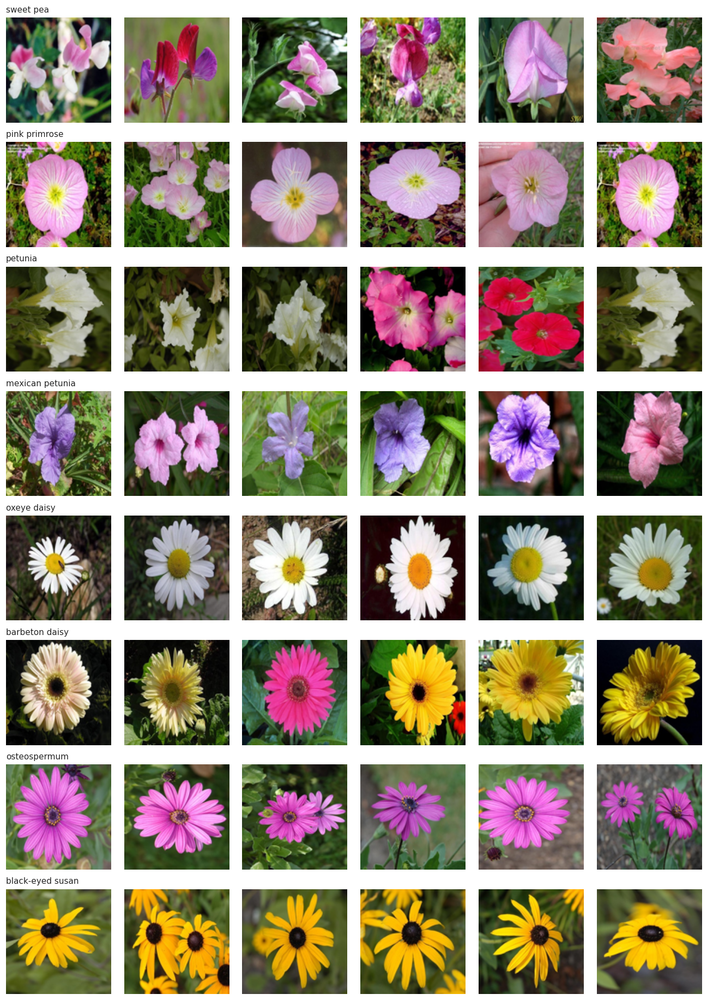

In [10]:
similar_groups = ["sweet pea", "pink primrose", "petunia", "mexican petunia",   # rosadas/moradas
                  "oxeye daisy", "barbeton daisy", "osteospermum", "black-eyed susan"]  # margaritas
fig, axes = plt.subplots(len(similar_groups), 6, figsize=(12, 2.1 * len(similar_groups)))
for row, cname in zip(axes, similar_groups):
    imgs = df[df["class_name"] == cname].sample(6, random_state=SEED, replace=True)
    for ax, (_, r) in zip(row, imgs.iterrows()):
        ax.imshow(load_rgb(r["filename"]).resize((120, 120))); ax.axis("off")
    row[0].set_title(cname, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

### 4.5 Análisis de color por clase
El color es una característica muy discriminativa en flores. Calculamos el color medio y el tono dominante de cada especie. Esto también justifica que en el aumento de datos **no** alteremos mucho el tono (*hue*), porque podríamos convertir una flor en otra.

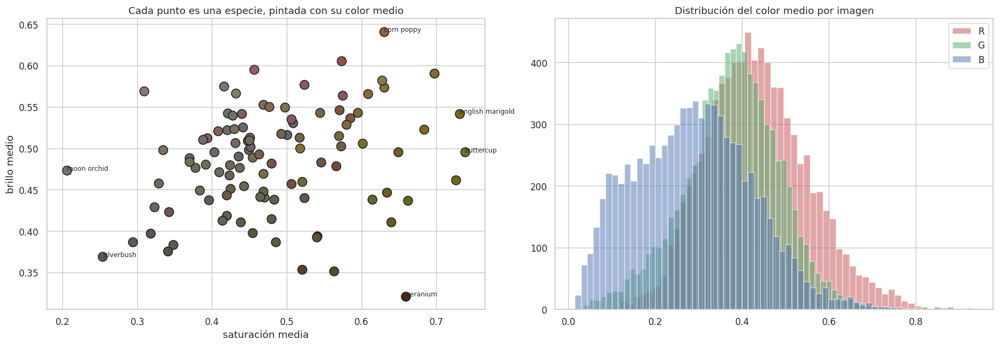

In [11]:
def color_stats(fname):
    im = load_rgb(fname).resize((64, 64))
    rgb = np.asarray(im, dtype=np.float32) / 255
    hsv = np.asarray(im.convert("HSV"), dtype=np.float32) / 255
    return rgb.reshape(-1, 3).mean(0), hsv[..., 1].mean(), hsv[..., 2].mean()

with ThreadPoolExecutor(8) as ex:
    cs = list(ex.map(color_stats, df["filename"]))
df["mean_rgb"] = [c[0] for c in cs]
df["saturation"] = [c[1] for c in cs]
df["brightness"] = [c[2] for c in cs]

class_color = df.groupby("class_name")["mean_rgb"].apply(lambda s: np.stack(s).mean(0))
class_sat = df.groupby("class_name")["saturation"].mean()
class_bri = df.groupby("class_name")["brightness"].mean()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for name in class_color.index:
    axes[0].scatter(class_sat[name], class_bri[name], color=class_color[name], s=120, edgecolor="k")
for name in class_sat.sort_values().index[[0, 1, -1, -2]].tolist() + class_bri.sort_values().index[[0, -1]].tolist():
    axes[0].annotate(name, (class_sat[name], class_bri[name]), fontsize=8)
axes[0].set_xlabel("saturación media"); axes[0].set_ylabel("brillo medio")
axes[0].set_title("Cada punto es una especie, pintada con su color medio")

for c, col in zip(range(3), ["r", "g", "b"]):
    vals = np.stack(df["mean_rgb"])[:, c]
    axes[1].hist(vals, bins=60, alpha=0.5, color=col, label=col.upper())
axes[1].set_title("Distribución del color medio por imagen"); axes[1].legend()
plt.tight_layout(); plt.show()

### 4.6 Visualización t-SNE con características de una red preentrenada
Pasamos todas las imágenes por una ResNet-18 preentrenada (sin entrenar nada) y proyectamos sus vectores de características a 2D con t-SNE. Si las especies forman grupos separados, las características aprendidas en ImageNet ya son útiles, y eso anticipa que el transfer learning funcionará bien. Los grupos que se mezclan indican especies difíciles.

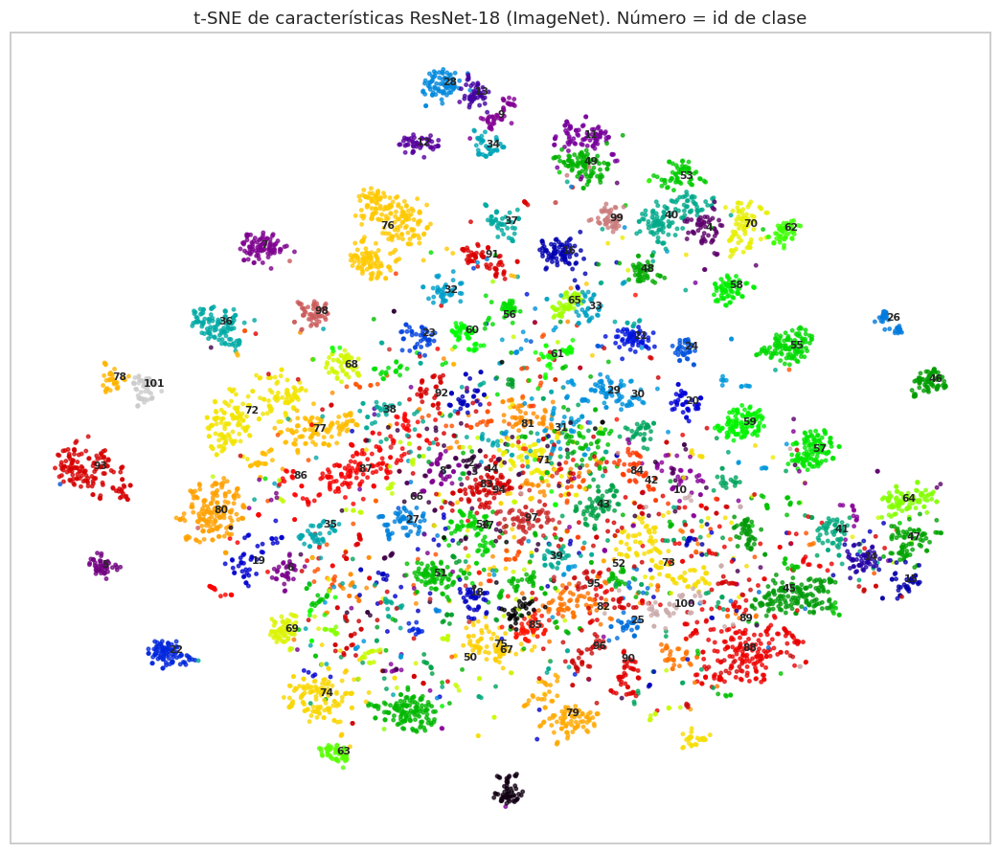

In [12]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

if RUN_TSNE:
    feat_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(IMG_SIZE),
                                  transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    r18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if PRETRAINED else None)
    r18.fc = nn.Identity(); r18 = r18.to(device).eval()

    class _Plain(Dataset):
        def __init__(self, files): self.files = files
        def __len__(self): return len(self.files)
        def __getitem__(self, i): return feat_tf(load_rgb(self.files[i]))

    feats = []
    with torch.no_grad():
        for xb in DataLoader(_Plain(df["filename"].tolist()), batch_size=128, num_workers=NUM_WORKERS):
            feats.append(r18(xb.to(device)).cpu())
    feats = torch.cat(feats).numpy()
    emb = TSNE(n_components=2, perplexity=min(30, len(df) - 1), init="pca", random_state=SEED).fit_transform(feats)

    fig, ax = plt.subplots(figsize=(12, 10))
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=df["label"], cmap="nipy_spectral", s=5, alpha=0.7)
    centers = pd.DataFrame(emb).groupby(df["label"].values).median()
    for lab, (x, y) in centers.iterrows():
        ax.text(x, y, str(lab), fontsize=7, weight="bold")
    ax.set_title("t-SNE de características ResNet-18 (ImageNet). Número = id de clase")
    ax.set_xticks([]); ax.set_yticks([]); plt.show()
    del r18

**Observaciones del t-SNE:** muchas especies forman **grupos compactos y separados** (por ejemplo, las de colores o formas muy característicos), aunque la red nunca vio estas flores ni sus etiquetas. Eso indica que las características de ImageNet ya distinguen bien la mayoría de especies, y anticipa que el **transfer learning** funcionará muy bien. En el centro del mapa hay una zona donde varias especies se **mezclan**: son las difíciles, con colores y formas parecidas, y ahí esperamos que se concentren los errores. Esto se confirma en la sección 9.3.

## 5. Preprocesamiento, partición y aumento de datos

### 5.1 Partición estratificada 70 / 15 / 15
La partición oficial de Oxford 102 deja solo **10 imágenes por clase para entrenamiento** (1.020 en total) y más de 6.000 para prueba. Es útil para comparar con artículos científicos, pero es muy poco para entrenar una CNN desde cero.
Por eso hacemos nuestra propia partición **estratificada**: cada clase conserva la misma proporción en entrenamiento, validación y prueba.

- **Entrenamiento (70 %)**: ajustar los pesos.
- **Validación (15 %)**: escoger hiperparámetros y hacer early stopping.
- **Prueba (15 %)**: se usa **una sola vez** al final, para reportar el rendimiento real.

Entrenamiento: 5729 | Validación: 1228 | Prueba: 1228


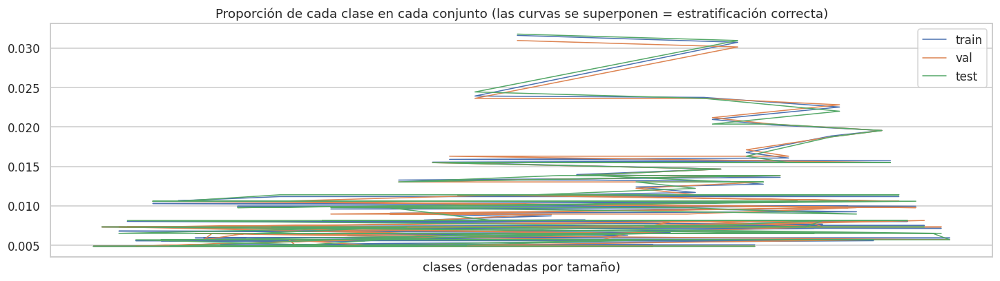

Mínimo de imágenes por clase en prueba: 6


In [13]:
train_df, temp_df = train_test_split(df, test_size=VAL_FRAC + TEST_FRAC, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                   stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print(f"Entrenamiento: {len(train_df)} | Validación: {len(val_df)} | Prueba: {len(test_df)}")

# Verificación: no hay imágenes repetidas entre conjuntos
assert not (set(train_df.md5) & set(val_df.md5)) and not (set(train_df.md5) & set(test_df.md5))

split_counts = pd.DataFrame({"train": train_df.label.value_counts(), "val": val_df.label.value_counts(),
                             "test": test_df.label.value_counts()}).sort_values("train", ascending=False)
ax = (split_counts / split_counts.sum()).plot(figsize=(16, 4), lw=1)
ax.set_title("Proporción de cada clase en cada conjunto (las curvas se superponen = estratificación correcta)")
ax.set_xticks([]); ax.set_xlabel("clases (ordenadas por tamaño)"); plt.show()
print("Mínimo de imágenes por clase en prueba:", split_counts["test"].min())

### 5.2 Normalización
Calculamos la media y la desviación estándar por canal en el conjunto de entrenamiento y las comparamos con las de ImageNet. Usamos las estadísticas de **ImageNet en ambos modelos**: son las que espera la red preentrenada y, como se ve abajo, son muy parecidas a las de nuestras imágenes.

In [14]:
acc_sum, acc_sq, n_px = np.zeros(3), np.zeros(3), 0
for f in train_df["filename"].sample(min(1000, len(train_df)), random_state=SEED):
    a = np.asarray(load_rgb(f).resize((128, 128)), dtype=np.float64) / 255
    acc_sum += a.sum((0, 1)); acc_sq += (a ** 2).sum((0, 1)); n_px += a.shape[0] * a.shape[1]
data_mean = acc_sum / n_px
data_std = np.sqrt(acc_sq / n_px - data_mean ** 2)
display(pd.DataFrame({"Oxford102 (train)": np.r_[data_mean, data_std].round(3),
                      "ImageNet": np.r_[IMAGENET_MEAN, IMAGENET_STD]},
                     index=["media R", "media G", "media B", "std R", "std G", "std B"]))

,Oxford102 (train),ImageNet
media R,0.432,0.485
media G,0.377,0.456
media B,0.287,0.406
std R,0.293,0.229
std G,0.242,0.224
std B,0.264,0.225


### 5.3 Aumento de datos (data augmentation)
Con ~56 imágenes de entrenamiento por clase, el aumento de datos es clave para evitar el sobreajuste. Cada transformación tiene una justificación:

| Transformación | Por qué |
|---|---|
| `RandomResizedCrop(224, scale=(0.6, 1))` | La flor aparece a distintas distancias y posiciones en la foto |
| `RandomHorizontalFlip` | Una flor reflejada sigue siendo la misma especie |
| `RandomRotation(20)` | Las fotos se toman con distintas inclinaciones |
| `ColorJitter(brillo, contraste, saturación, hue=0.02)` | Simula cambios de luz. El **tono casi no se altera** porque el color identifica la especie (sección 4.5) |
| `RandomErasing(p=0.25)` | Simula oclusiones (hojas, insectos, otras flores) y obliga a usar varias partes de la flor |
| `GaussianBlur` (p=0,2) y ruido gaussiano (p=0,2) | **Agregados después de la corrida 1:** la prueba de robustez (sección 10.2) mostró que el desenfoque y el ruido eran lo que más hacía fallar a los modelos (el Modelo A caía a 12 % y 9 % de accuracy). Simulan fotos movidas o tomadas con poca luz y celulares de gama baja. Se activan con `ROBUST_AUG = True` |

En validación y prueba **no** se aumenta: solo se redimensiona y se recorta al centro.

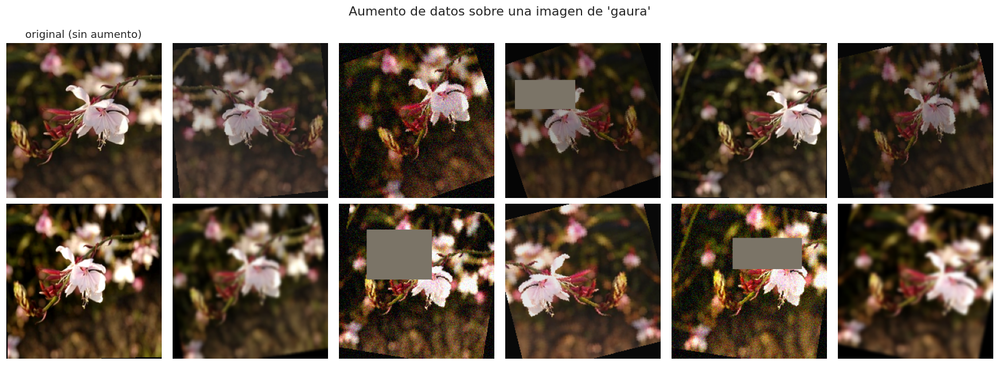

In [15]:
class AddGaussianNoise:
    """Ruido gaussiano sobre el tensor (valores en [0, 1]), aplicado con probabilidad p."""
    def __init__(self, std=0.08, p=0.2):
        self.std, self.p = std, p
    def __call__(self, t):
        if random.random() < self.p:
            t = (t + torch.randn_like(t) * self.std).clamp(0, 1)
        return t

robust_steps = ([transforms.RandomApply([transforms.GaussianBlur(9, sigma=(0.5, 3.0))], p=0.2)]
                if ROBUST_AUG else [])
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.02),
    *robust_steps,
    transforms.ToTensor(),
    *([AddGaussianNoise(0.08, 0.2)] if ROBUST_AUG else []),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])
eval_tf = transforms.Compose([
    transforms.Resize(RESIZE_SHORT_SIDE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def denorm(t):
    t = t.detach().cpu() * torch.tensor(IMAGENET_STD)[:, None, None] + torch.tensor(IMAGENET_MEAN)[:, None, None]
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

example = train_df.iloc[0]
img = load_rgb(example["filename"])
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
axes[0, 0].imshow(denorm(eval_tf(img))); axes[0, 0].set_title("original (sin aumento)")
for ax in axes.flat[1:]:
    ax.imshow(denorm(train_tf(img)))
for ax in axes.flat: ax.axis("off")
plt.suptitle(f"Aumento de datos sobre una imagen de '{example['class_name']}'"); plt.tight_layout(); plt.show()

### 5.4 Dataset de PyTorch y manejo del desbalance
Para que el modelo no favorezca las clases grandes usamos un **`WeightedRandomSampler`**: cada imagen se muestrea con probabilidad inversamente proporcional al tamaño de su clase. Así, en cada época el modelo ve aproximadamente el mismo número de ejemplos de cada especie (las clases pequeñas se repiten, pero con aumentos distintos cada vez).

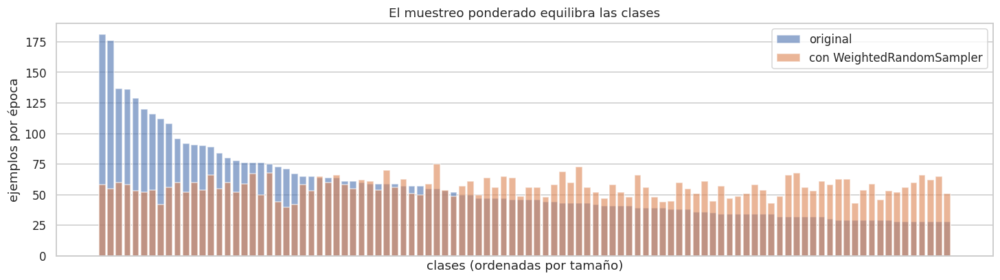

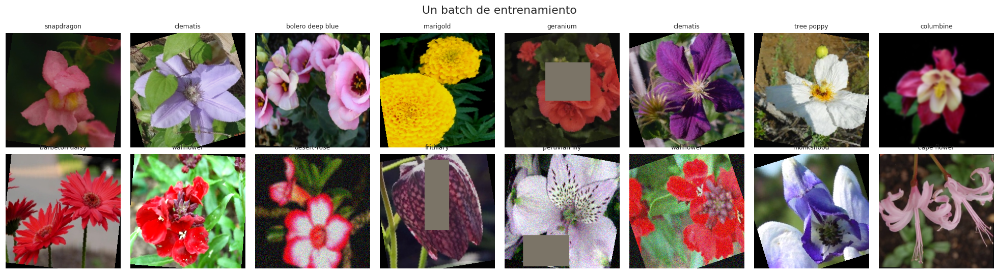

In [16]:
class FlowerDataset(Dataset):
    def __init__(self, frame, transform, root=RESIZED_DIR, pil_corruption=None):
        self.files = frame["filename"].tolist()
        self.labels = frame["label"].tolist()
        self.transform, self.root, self.pil_corruption = transform, root, pil_corruption
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = load_rgb(self.files[i], self.root)
        if self.pil_corruption is not None:
            img = self.pil_corruption(img)
        return self.transform(img), self.labels[i]

class_counts = train_df["label"].value_counts().sort_index().values
sample_weights = 1.0 / class_counts[train_df["label"].values]
sampler = WeightedRandomSampler(torch.as_tensor(sample_weights, dtype=torch.double),
                                num_samples=len(train_df), replacement=True)

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"),
                 persistent_workers=NUM_WORKERS > 0)
train_ds = FlowerDataset(train_df, train_tf)
train_loader = DataLoader(train_ds, sampler=sampler, drop_last=True, **loader_kw)
train_loader_unbalanced = DataLoader(train_ds, shuffle=True, drop_last=True, **loader_kw)  # para la ablación
val_loader = DataLoader(FlowerDataset(val_df, eval_tf), shuffle=False, **loader_kw)
test_loader = DataLoader(FlowerDataset(test_df, eval_tf), shuffle=False, **loader_kw)

# Efecto del sampler: etiquetas que vería el modelo en una época
drawn = np.bincount(train_df["label"].values[list(iter(sampler))], minlength=NUM_CLASSES)
fig, ax = plt.subplots(figsize=(16, 4))
order = np.argsort(-class_counts)
ax.bar(range(NUM_CLASSES), class_counts[order], alpha=0.6, label="original")
ax.bar(range(NUM_CLASSES), drawn[order], alpha=0.6, label="con WeightedRandomSampler")
ax.set_xticks([]); ax.set_xlabel("clases (ordenadas por tamaño)"); ax.set_ylabel("ejemplos por época")
ax.set_title("El muestreo ponderado equilibra las clases"); ax.legend(); plt.show()

xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(denorm(x)); ax.set_title(CLASS_NAMES[y][:18], fontsize=8); ax.axis("off")
plt.suptitle("Un batch de entrenamiento"); plt.tight_layout(); plt.show()

### 5.5 Funciones de entrenamiento
Bucle de entrenamiento con:
- **Precisión mixta (AMP)** en GPU: entrena más rápido y usa menos memoria.
- **Scheduler por batch** (OneCycle o coseno).
- **Early stopping** sobre la accuracy de validación; se guarda el mejor checkpoint.
- Registro del historial (pérdida, accuracy y learning rate) para el monitoreo.

In [17]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None, scheduler=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device, dtype=torch.float16 if device == "cuda" else torch.bfloat16,
                                enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
            loss_sum += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return loss_sum / total, correct / total


def fit(model, name, train_loader, val_loader, criterion, optimizer, scheduler, epochs, patience=PATIENCE):
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    val_criterion = nn.CrossEntropyLoss()
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
    best_acc, best_state, bad_epochs = -1, None, 0
    ckpt = Path(CHECKPOINT_DIR) / f"{name}.pt"
    t0 = time.time()
    for ep in range(1, epochs + 1):
        lr = optimizer.param_groups[-1]["lr"]
        tl, ta = run_epoch(model, train_loader, criterion, optimizer, scaler, scheduler)
        vl, va = run_epoch(model, val_loader, val_criterion)
        for k, v in zip(hist, [tl, ta, vl, va, lr]):
            hist[k].append(v)
        flag = ""
        if va > best_acc:
            best_acc, bad_epochs, flag = va, 0, "  *mejor*"
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, ckpt)
        else:
            bad_epochs += 1
        print(f"[{name}] época {ep:02d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f} | lr {lr:.2e} | {time.time() - t0:.0f}s{flag}")
        if bad_epochs >= patience:
            print(f"Early stopping: {patience} épocas sin mejorar.")
            break
    model.load_state_dict(best_state)
    hist["train_time_s"] = time.time() - t0
    hist["best_val_acc"] = best_acc
    return hist


def plot_history(histories, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for name, h in histories.items():
        ep = range(1, len(h["train_loss"]) + 1)
        l = axes[0].plot(ep, h["train_loss"], "--", label=f"{name} train")[0]
        axes[0].plot(ep, h["val_loss"], color=l.get_color(), label=f"{name} val")
        axes[1].plot(ep, h["train_acc"], "--", color=l.get_color(), label=f"{name} train")
        axes[1].plot(ep, h["val_acc"], color=l.get_color(), label=f"{name} val")
        axes[2].plot(ep, h["lr"], color=l.get_color(), label=name)
    axes[0].set_title("Pérdida"); axes[1].set_title("Accuracy"); axes[2].set_title("Learning rate (inicio de época)")
    axes[2].set_yscale("log")
    for ax in axes: ax.set_xlabel("época"); ax.legend(fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

## 6. Modelo A: CNN propia desde cero

### 6.1 Arquitectura: *FlowerNet*
Diseñamos una CNN residual pequeña (~6,6 M de parámetros) con atención de canales **Squeeze-and-Excitation (SE)**.

| Bloque | Salida (para 224×224) | Justificación |
|---|---|---|
| **Stem**: Conv 3×3 s2 (32) → BN → ReLU → Conv 3×3 (64) → BN → ReLU → MaxPool | 64 × 56 × 56 | Reduce rápido la resolución para ahorrar cómputo y extrae bordes y colores básicos |
| **Etapa 1**: 2 bloques residuales SE (64) | 64 × 56 × 56 | Texturas simples (venas de los pétalos, bordes) |
| **Etapa 2**: 2 bloques residuales SE (128), stride 2 | 128 × 28 × 28 | Patrones más complejos (formas de pétalos) |
| **Etapa 3**: 2 bloques residuales SE (256), stride 2 | 256 × 14 × 14 | Partes de la flor (centro, corola) |
| **Etapa 4**: 1 bloque residual SE (512), stride 2 | 512 × 7 × 7 | Conceptos de alto nivel (forma global de la flor) |
| **Global Average Pooling** | 512 | Reemplaza capas densas grandes: menos parámetros y menos sobreajuste |
| **Dropout (0,4)** → **Linear (102)** | 102 | Regularización y clasificación |

**Componentes clave:**
- **Conexiones residuales** (ResNet, He et al. 2016): la salida de cada bloque es `F(x) + x`. El gradiente fluye directo por el atajo, así que se pueden entrenar redes más profundas sin que el gradiente se desvanezca.
- **Batch Normalization** después de cada convolución: estabiliza la distribución de activaciones, permite learning rates más altos y actúa como regularizador.
- **Squeeze-and-Excitation** (Hu et al. 2018), un mecanismo de **atención por canal**: resume cada canal con un promedio global y aprende un peso entre 0 y 1 para cada uno. Así la red puede enfatizar los canales útiles (por ejemplo, los que responden a cierto color o textura de pétalo) y atenuar los del fondo.
- **Dropout** antes de la capa final y **label smoothing** en la pérdida, para reducir el sobreajuste con pocas imágenes por clase.

In [18]:
class SEBlock(nn.Module):
    """Atención por canal: squeeze (promedio global) + excitation (MLP con sigmoide)."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(channels, channels // reduction), nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels), nn.Sigmoid())
    def forward(self, x):
        return x * self.fc(x)[:, :, None, None]


class ResidualSEBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1, use_se=True, use_residual=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.se = SEBlock(out_c) if use_se else nn.Identity()
        self.use_residual = use_residual
        self.shortcut = nn.Identity()
        if stride != 1 or in_c != out_c:     # proyección 1x1 cuando cambian las dimensiones
            self.shortcut = nn.Sequential(nn.Conv2d(in_c, out_c, 1, stride, bias=False), nn.BatchNorm2d(out_c))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.se(self.bn2(self.conv2(out)))
        if self.use_residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class FlowerNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, use_se=True, use_residual=True, dropout=0.4):
        super().__init__()
        kw = dict(use_se=use_se, use_residual=use_residual)
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1))
        self.stage1 = nn.Sequential(ResidualSEBlock(64, 64, 1, **kw), ResidualSEBlock(64, 64, 1, **kw))
        self.stage2 = nn.Sequential(ResidualSEBlock(64, 128, 2, **kw), ResidualSEBlock(128, 128, 1, **kw))
        self.stage3 = nn.Sequential(ResidualSEBlock(128, 256, 2, **kw), ResidualSEBlock(256, 256, 1, **kw))
        self.stage4 = nn.Sequential(ResidualSEBlock(256, 512, 2, **kw))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(512, num_classes))
        for m in self.modules():                # inicialización de He para capas con ReLU
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        x = self.stem(x)
        x = self.stage4(self.stage3(self.stage2(self.stage1(x))))
        return self.head(x)


model_a = FlowerNet().to(device)
print("Parámetros (total, entrenables):", count_params(model_a))
try:
    from torchinfo import summary
    print(summary(model_a, input_size=(1, 3, IMG_SIZE, IMG_SIZE), depth=2, verbose=0,
                  col_names=("output_size", "num_params")))
except ImportError:
    print(model_a)

Parámetros (total, entrenables): (6573918, 6573918)
Layer (type:depth-idx)                             Output Shape              Param #
FlowerNet                                          [1, 102]                  --
├─Sequential: 1-1                                  [1, 64, 56, 56]           --
│    └─Conv2d: 2-1                                 [1, 32, 112, 112]         864
│    └─BatchNorm2d: 2-2                            [1, 32, 112, 112]         64
│    └─ReLU: 2-3                                   [1, 32, 112, 112]         --
│    └─Conv2d: 2-4                                 [1, 64, 112, 112]         18,432
│    └─BatchNorm2d: 2-5                            [1, 64, 112, 112]         128
│    └─ReLU: 2-6                                   [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-7                              [1, 64, 56, 56]           --
├─Sequential: 1-2                                  [1, 64, 56, 56]           --
│    └─ResidualSEBlock: 2-8                        [1, 64

### 6.2 Búsqueda del learning rate (LR range test)
Antes de entrenar hacemos un *LR range test* (Smith, 2017): durante unas iteraciones subimos el learning rate de forma exponencial y registramos la pérdida. El LR máximo debe quedar en la zona donde la pérdida **baja más rápido**, antes del mínimo y lejos del punto donde diverge.

**Registro de experimentos (corrida 1 → corrida 2):**

| | Corrida 1 (9 nov) | Corrida 2 (este notebook) | Por qué |
|---|---|---|---|
| Regla del LR máximo | mínimo / 10 → **4e-4** | mínimo / 3 → ~**1,7e-3** | En la corrida 1 la pérdida del range test tuvo su mínimo cerca de 5e-3. La regla /10 dio un LR muy conservador y el modelo **seguía mejorando en la última época** (val acc 0,797 en la época 38 de 40): subajuste |
| Épocas del Modelo A | 40 | 50 | Por la misma razón: la curva de validación no se había estabilizado |
| Aumento de datos | estándar | + desenfoque y ruido | La robustez ante desenfoque y ruido fue muy baja (sección 10.2) |
| Weight decay en el grid | {0; 1e-4} | {0; 1e-2; 1e-1} | 0 y 1e-4 dieron exactamente el mismo resultado: el rango era demasiado pequeño para tener efecto |
| Calibración | sin corregir | + temperature scaling | Los dos modelos eran subconfiados (ECE 0,117 y 0,197), por el label smoothing |

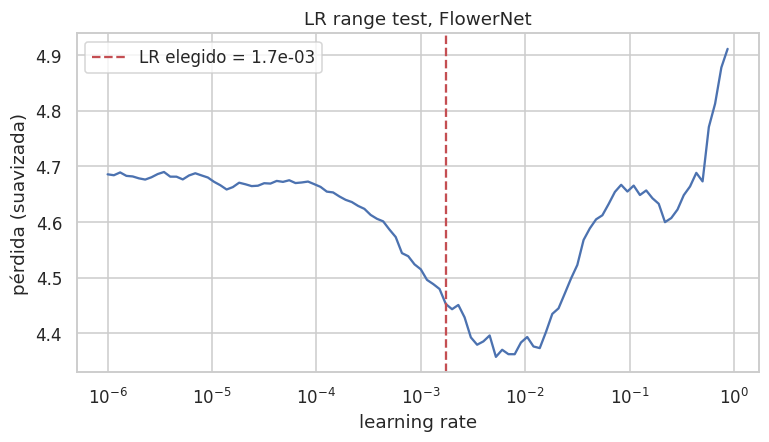

In [19]:
def lr_range_test(model_fn, loader, start_lr=1e-6, end_lr=1.0, steps=100):
    model = model_fn().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=start_lr, weight_decay=5e-4)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    mult = (end_lr / start_lr) ** (1 / steps)
    lrs, losses, avg, best = [], [], 0.0, float("inf")
    it = iter(loader)
    model.train()
    for i in range(steps):
        try:
            x, y = next(it)
        except StopIteration:
            it = iter(loader); x, y = next(it)
        x, y = x.to(device), y.to(device)
        loss = crit(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
        avg = 0.9 * avg + 0.1 * loss.item()
        smooth = avg / (1 - 0.9 ** (i + 1))
        lrs.append(opt.param_groups[0]["lr"]); losses.append(smooth)
        best = min(best, smooth)
        if smooth > 4 * best:
            break
        for g in opt.param_groups:
            g["lr"] *= mult
    return np.array(lrs), np.array(losses)

lrs, losses = lr_range_test(FlowerNet, train_loader, steps=30 if QUICK_RUN else 100)
MAX_LR_SCRATCH = float(np.clip(lrs[np.argmin(losses)] / 3, 3e-4, 3e-3))   # corrida 1 usaba /10 (ver tabla)
plt.figure(figsize=(8, 4)); plt.plot(lrs, losses); plt.xscale("log")
plt.axvline(MAX_LR_SCRATCH, color="r", ls="--", label=f"LR elegido = {MAX_LR_SCRATCH:.1e}")
plt.xlabel("learning rate"); plt.ylabel("pérdida (suavizada)"); plt.title("LR range test, FlowerNet"); plt.legend(); plt.show()

### 6.3 Entrenamiento del Modelo A
- **Optimizador AdamW** (Adam con weight decay desacoplado, que regulariza mejor que la penalización L2 en Adam).
- **OneCycleLR**: el LR sube durante el primer 30 % del entrenamiento y luego baja con un coseno. Converge más rápido y generaliza mejor que un LR fijo.
- **CrossEntropy con label smoothing = 0,1**: evita que el modelo sea demasiado confiado.

[modelA_flowernet] época 01/50 | train loss 4.457 acc 0.042 | val loss 3.997 acc 0.084 | lr 7.00e-05 | 57s  *mejor*
[modelA_flowernet] época 02/50 | train loss 4.047 acc 0.106 | val loss 3.616 acc 0.168 | lr 8.84e-05 | 113s  *mejor*
[modelA_flowernet] época 03/50 | train loss 3.753 acc 0.159 | val loss 3.292 acc 0.197 | lr 1.43e-04 | 168s  *mejor*
[modelA_flowernet] época 04/50 | train loss 3.519 acc 0.194 | val loss 3.219 acc 0.195 | lr 2.31e-04 | 224s
[modelA_flowernet] época 05/50 | train loss 3.359 acc 0.228 | val loss 3.017 acc 0.243 | lr 3.48e-04 | 280s  *mejor*
[modelA_flowernet] época 06/50 | train loss 3.190 acc 0.275 | val loss 2.843 acc 0.280 | lr 4.90e-04 | 336s  *mejor*
[modelA_flowernet] época 07/50 | train loss 3.088 acc 0.305 | val loss 2.927 acc 0.275 | lr 6.51e-04 | 392s
[modelA_flowernet] época 08/50 | train loss 2.997 acc 0.332 | val loss 2.782 acc 0.283 | lr 8.23e-04 | 447s  *mejor*
[modelA_flowernet] época 09/50 | train loss 2.841 acc 0.376 | val loss 2.516 acc 0.

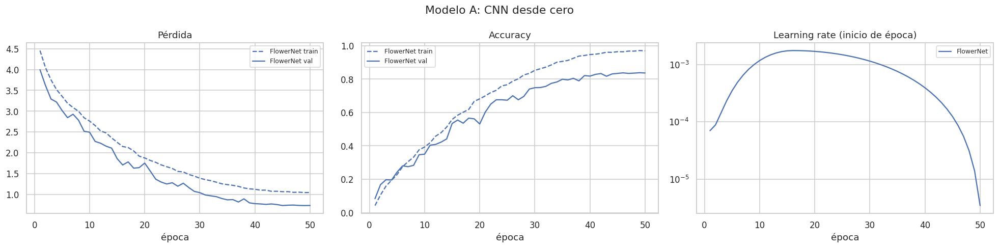

In [20]:
seed_everything()
model_a = FlowerNet().to(device)
opt_a = torch.optim.AdamW(model_a.parameters(), lr=MAX_LR_SCRATCH, weight_decay=5e-4)
sched_a = torch.optim.lr_scheduler.OneCycleLR(opt_a, max_lr=MAX_LR_SCRATCH, epochs=EPOCHS_SCRATCH,
                                              steps_per_epoch=len(train_loader), pct_start=0.3)
crit_smooth = nn.CrossEntropyLoss(label_smoothing=0.1)
hist_a = fit(model_a, "modelA_flowernet", train_loader, val_loader, crit_smooth, opt_a, sched_a,
             EPOCHS_SCRATCH, patience=max(PATIENCE, EPOCHS_SCRATCH // 3))
print(f"Tiempo de entrenamiento: {hist_a['train_time_s'] / 60:.1f} min | mejor val acc: {hist_a['best_val_acc']:.3f}")
plot_history({"FlowerNet": hist_a}, "Modelo A: CNN desde cero")

### 6.4 (Opcional) Ablación: ¿cuánto aporta cada componente?
Entrenamos variantes de FlowerNet con el mismo presupuesto corto (8 épocas): sin atención SE, sin conexiones residuales y sin muestreo balanceado. Así justificamos con datos cada decisión de diseño. Se controla con `RUN_ABLATION` (~25 minutos con GPU; mucho más en CPU).

> Como el presupuesto es corto, la ablación compara **qué tan rápido aprende** cada variante, no su rendimiento final. Las diferencias pequeñas (±1–2 puntos) pueden deberse al azar.

[ablation_completa] época 01/8 | train loss 4.334 acc 0.054 | val loss 3.674 acc 0.117 | lr 7.00e-05 | 56s  *mejor*
[ablation_completa] época 02/8 | train loss 3.786 acc 0.126 | val loss 3.631 acc 0.125 | lr 6.97e-04 | 112s  *mejor*
[ablation_completa] época 03/8 | train loss 3.488 acc 0.185 | val loss 2.992 acc 0.212 | lr 1.64e-03 | 169s  *mejor*
[ablation_completa] época 04/8 | train loss 3.176 acc 0.271 | val loss 2.671 acc 0.309 | lr 1.70e-03 | 226s  *mejor*
[ablation_completa] época 05/8 | train loss 2.970 acc 0.334 | val loss 2.490 acc 0.349 | lr 1.42e-03 | 283s  *mejor*
[ablation_completa] época 06/8 | train loss 2.742 acc 0.406 | val loss 2.232 acc 0.419 | lr 9.67e-04 | 341s  *mejor*
[ablation_completa] época 07/8 | train loss 2.587 acc 0.453 | val loss 2.134 acc 0.447 | lr 4.90e-04 | 397s  *mejor*
[ablation_completa] época 08/8 | train loss 2.547 acc 0.467 | val loss 2.072 acc 0.475 | lr 1.31e-04 | 453s  *mejor*
[ablation_sin_SE] época 01/8 | train loss 4.320 acc 0.054 | val l

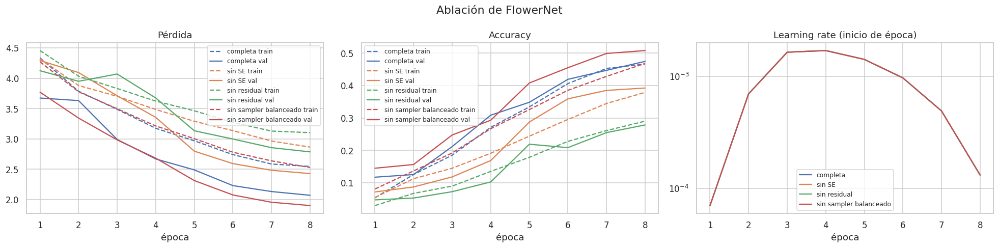

,mejor val acc
completa,0.475
sin SE,0.393
sin residual,0.279
sin sampler balanceado,0.508


In [21]:
ablation_results = {}
if RUN_ABLATION:
    ABL_EPOCHS = 3 if QUICK_RUN else 8
    variants = {
        "completa": (dict(), train_loader),
        "sin SE": (dict(use_se=False), train_loader),
        "sin residual": (dict(use_residual=False), train_loader),
        "sin sampler balanceado": (dict(), train_loader_unbalanced),
    }
    abl_hist = {}
    for name, (kw, loader) in variants.items():
        seed_everything()
        m = FlowerNet(**kw).to(device)
        o = torch.optim.AdamW(m.parameters(), lr=MAX_LR_SCRATCH, weight_decay=5e-4)
        s = torch.optim.lr_scheduler.OneCycleLR(o, max_lr=MAX_LR_SCRATCH, epochs=ABL_EPOCHS,
                                                steps_per_epoch=len(loader), pct_start=0.3)
        abl_hist[name] = fit(m, f"ablation_{name.replace(' ', '_')}", loader, val_loader, crit_smooth, o, s,
                             ABL_EPOCHS, patience=ABL_EPOCHS)
        ablation_results[name] = abl_hist[name]["best_val_acc"]
        del m
    plot_history(abl_hist, "Ablación de FlowerNet")
    display(pd.Series(ablation_results, name="mejor val acc").to_frame().style.format("{:.3f}"))

## 7. Experimentación con hiperparámetros (cabeza de clasificación del Modelo B)
Entrenar la ResNet completa para cada combinación de hiperparámetros sería muy costoso. Como en la fase 1 del transfer learning el *backbone* está congelado, podemos **extraer las características una sola vez** y entrenar la capa final con muchas combinaciones en segundos:

- learning rate ∈ {1e-2, 3e-3, 1e-3, 3e-4}
- dropout ∈ {0; 0,3; 0,5}
- weight decay ∈ {0; 1e-2; 1e-1}

Las 36 combinaciones se comparan en validación y la mejor se usa en la sección 8.

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 145MB/s]


Características extraídas: (5729, 2048) en 16s


,lr,dropout,weight_decay,val_acc
0,1e-02,0.000000,0.100000,0.955
1,3e-03,0.000000,0.100000,0.955
2,1e-02,0.000000,0.010000,0.954
3,1e-02,0.000000,0.000000,0.954
4,3e-03,0.000000,0.010000,0.954
5,3e-03,0.000000,0.000000,0.954
6,3e-03,0.300000,0.010000,0.950
7,3e-03,0.300000,0.000000,0.950
8,3e-03,0.300000,0.100000,0.950
9,1e-02,0.300000,0.100000,0.949


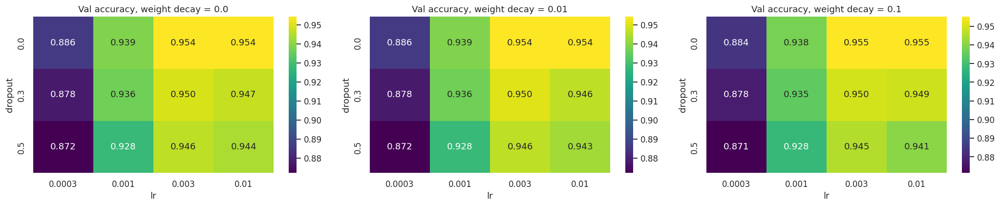

Mejores hiperparámetros para la cabeza: {'lr': 0.01, 'dropout': 0.0, 'weight_decay': 0.1, 'val_acc': 0.9552116990089417}


In [22]:
def build_tl_model(dropout=0.3, pretrained=PRETRAINED, arch=TL_ARCH):
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    else:
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, NUM_CLASSES))
    return m

backbone = build_tl_model()
backbone.fc = nn.Identity()
backbone = backbone.to(device).eval()

@torch.no_grad()
def extract(frame):
    dl = DataLoader(FlowerDataset(frame, eval_tf), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    fs, ys = [], []
    for x, y in dl:
        with torch.autocast(device_type=device, enabled=USE_AMP):
            fs.append(backbone(x.to(device)).float().cpu())
        ys.append(y)
    return torch.cat(fs), torch.cat(ys)

t0 = time.time()
Xtr, ytr = extract(train_df)
Xva, yva = extract(val_df)
print(f"Características extraídas: {tuple(Xtr.shape)} en {time.time() - t0:.0f}s")
del backbone

def train_head(lr, dropout, wd, epochs=30 if not QUICK_RUN else 5, bs=256):
    torch.manual_seed(SEED)
    head = nn.Sequential(nn.Dropout(dropout), nn.Linear(Xtr.shape[1], NUM_CLASSES)).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    w = torch.as_tensor(sample_weights, dtype=torch.double)
    Xg, yg, Xv, yv = Xtr.to(device), ytr.to(device), Xva.to(device), yva.to(device)
    best = 0
    for _ in range(epochs):
        head.train()
        idx = torch.multinomial(w, len(w), replacement=True).to(device)   # mismo muestreo balanceado
        for b in range(0, len(idx), bs):
            j = idx[b:b + bs]
            loss = F.cross_entropy(head(Xg[j]), yg[j], label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        head.eval()
        with torch.no_grad():
            best = max(best, (head(Xv).argmax(1) == yv).float().mean().item())
    return best

grid = []
for lr in [1e-2, 3e-3, 1e-3, 3e-4]:
    for dp in [0.0, 0.3, 0.5]:
        for wd in [0.0, 1e-2, 1e-1]:
            grid.append(dict(lr=lr, dropout=dp, weight_decay=wd, val_acc=train_head(lr, dp, wd)))
grid = pd.DataFrame(grid).sort_values("val_acc", ascending=False).reset_index(drop=True)
display(grid.head(10).style.format({"lr": "{:.0e}", "val_acc": "{:.3f}"}))

best_hp = grid.iloc[0].to_dict()
fig, axes = plt.subplots(1, 3, figsize=(19, 4))
for ax, wd in zip(axes, [0.0, 1e-2, 1e-1]):
    piv = grid[grid.weight_decay == wd].pivot(index="dropout", columns="lr", values="val_acc")
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(f"Val accuracy, weight decay = {wd}")
plt.tight_layout(); plt.show()
print("Mejores hiperparámetros para la cabeza:", best_hp)

**Observaciones (corrida 1):** el **learning rate** es el hiperparámetro que más importa: con 3e-4 la cabeza llega a ~0,88 de val accuracy y con 3e-3 o 1e-2 sube a ~0,95. El **dropout** casi no ayuda en la cabeza: el mejor resultado fue sin dropout, porque las características de ResNet-50 ya son muy generales y una sola capa lineal sobre ellas tiene poco riesgo de sobreajuste. El weight decay de 0 y 1e-4 dio resultados idénticos, así que en esta corrida ampliamos el rango a {0; 1e-2; 1e-1}.

## 8. Modelo B: transfer learning con ResNet-50 (ResNet-18 en CPU)

**ResNet-50** (He et al., 2016) preentrenada en ImageNet (1,2 M de imágenes, 1.000 clases) ya sabe detectar bordes, texturas, formas y partes de objetos. Reutilizamos ese conocimiento y solo adaptamos la red a nuestras 102 especies. Así se puede llegar a una precisión alta con pocas imágenes por clase.

**Estrategia en dos fases:**
1. **Fase 1, solo la cabeza** (backbone congelado): se entrena la nueva capa `Dropout → Linear(2048, 102)` con los mejores hiperparámetros de la sección 7. Así se evita que los gradientes grandes de una capa aleatoria dañen los pesos preentrenados.
2. **Fase 2, fine-tuning completo**: se descongela toda la red y se entrena con **learning rates diferenciados**: 10 veces menor en el backbone que en la cabeza. Las primeras capas (bordes, colores) casi no deben cambiar; las últimas se especializan en flores.

Fase 1, parámetros (total, entrenables): (23717030, 208998)
[modelB_phase1] época 01/5 | train loss 2.328 acc 0.622 | val loss 0.854 acc 0.810 | lr 1.00e-02 | 55s  *mejor*
[modelB_phase1] época 02/5 | train loss 1.521 acc 0.834 | val loss 0.622 acc 0.875 | lr 9.05e-03 | 111s  *mejor*
[modelB_phase1] época 03/5 | train loss 1.362 acc 0.885 | val loss 0.563 acc 0.903 | lr 6.55e-03 | 166s  *mejor*
[modelB_phase1] época 04/5 | train loss 1.273 acc 0.916 | val loss 0.526 acc 0.923 | lr 3.45e-03 | 221s  *mejor*
[modelB_phase1] época 05/5 | train loss 1.240 acc 0.926 | val loss 0.527 acc 0.924 | lr 9.55e-04 | 276s  *mejor*
Fase 2, parámetros (total, entrenables): (23717030, 23717030)
[modelB_resnet50] época 01/12 | train loss 1.197 acc 0.936 | val loss 0.470 acc 0.936 | lr 4.00e-05 | 61s  *mejor*
[modelB_resnet50] época 02/12 | train loss 1.090 acc 0.963 | val loss 0.413 acc 0.954 | lr 3.99e-04 | 124s  *mejor*
[modelB_resnet50] época 03/12 | train loss 1.017 acc 0.980 | val loss 0.407 acc 0.9

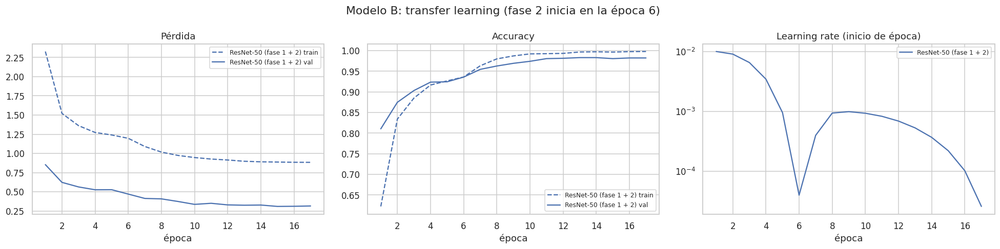

In [23]:
seed_everything()
model_b = build_tl_model(dropout=best_hp["dropout"]).to(device)

# ---------- Fase 1: backbone congelado ----------
for name, p in model_b.named_parameters():
    p.requires_grad = name.startswith("fc.")
print("Fase 1, parámetros (total, entrenables):", count_params(model_b))
opt_b1 = torch.optim.AdamW(model_b.fc.parameters(), lr=best_hp["lr"], weight_decay=best_hp["weight_decay"])
sched_b1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_b1, T_max=EPOCHS_TL_HEAD * len(train_loader))
hist_b1 = fit(model_b, "modelB_phase1", train_loader, val_loader, crit_smooth, opt_b1, sched_b1, EPOCHS_TL_HEAD)

# ---------- Fase 2: fine-tuning de toda la red ----------
for p in model_b.parameters():
    p.requires_grad = True
print("Fase 2, parámetros (total, entrenables):", count_params(model_b))
head_params = list(model_b.fc.parameters())
backbone_params = [p for n, p in model_b.named_parameters() if not n.startswith("fc.")]
opt_b2 = torch.optim.AdamW([{"params": backbone_params, "lr": 1e-4},
                            {"params": head_params, "lr": 1e-3}], weight_decay=1e-4)
sched_b2 = torch.optim.lr_scheduler.OneCycleLR(opt_b2, max_lr=[1e-4, 1e-3], epochs=EPOCHS_TL_FT,
                                               steps_per_epoch=len(train_loader), pct_start=0.2)
hist_b2 = fit(model_b, f"modelB_{TL_ARCH}", train_loader, val_loader, crit_smooth, opt_b2, sched_b2, EPOCHS_TL_FT)

# Historial combinado de las dos fases
hist_b = {k: hist_b1[k] + hist_b2[k] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
hist_b["train_time_s"] = hist_b1["train_time_s"] + hist_b2["train_time_s"]
hist_b["best_val_acc"] = hist_b2["best_val_acc"]
print(f"Tiempo total: {hist_b['train_time_s'] / 60:.1f} min | mejor val acc: {hist_b['best_val_acc']:.3f}")
plot_history({f"{TL_NAME} (fase 1 + 2)": hist_b}, f"Modelo B: transfer learning (fase 2 inicia en la época {len(hist_b1['train_loss']) + 1})")

### 8.1 Comparación de las curvas de entrenamiento

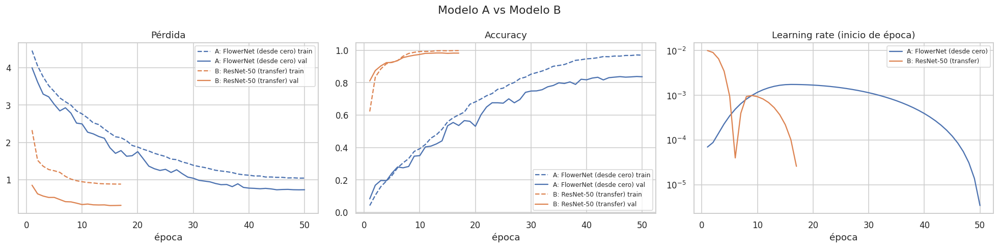

In [24]:
plot_history({"A: FlowerNet (desde cero)": hist_a, f"B: {TL_NAME} (transfer)": hist_b}, "Modelo A vs Modelo B")

## 9. Evaluación y análisis de resultados
Evaluamos ambos modelos con varias métricas. Las métricas *macro* dan el mismo peso a cada clase, lo cual es importante porque el dataset está desbalanceado:

- **Accuracy** y **accuracy balanceada** (promedio del recall por clase)
- **Precisión, recall y F1 macro**
- **Top-5 accuracy**: si la especie correcta está entre las 5 más probables (útil en una app que sugiere opciones)
- **ROC-AUC** y **PR-AUC** macro (uno contra todos)
- **Log-loss**: qué tan bien calibradas están las probabilidades

Los hiperparámetros y el modelo final se escogen con **validación**. El conjunto de **prueba** solo se usa para reportar.

In [25]:
@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = x.to(device)
        with torch.autocast(device_type=device, enabled=USE_AMP):
            logits = model(x).float()
            if tta:                                   # test-time augmentation: original + espejo
                logits = (logits.softmax(1) + model(torch.flip(x, dims=[3])).float().softmax(1)).log()
        P.append(logits.float().softmax(1).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()


def compute_metrics(probs, y):
    pred = probs.argmax(1)
    yb = label_binarize(y, classes=range(NUM_CLASSES))
    present = yb.sum(0) > 0
    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y, pred, average="weighted", zero_division=0),
        "top5_accuracy": top_k_accuracy_score(y, probs, k=5, labels=list(range(NUM_CLASSES))),
        "roc_auc_macro": roc_auc_score(yb[:, present], probs[:, present], average="macro"),
        "pr_auc_macro": average_precision_score(yb[:, present], probs[:, present], average="macro"),
        "log_loss": log_loss(y, np.clip(probs, 1e-7, 1), labels=list(range(NUM_CLASSES))),
    }


def latency_ms(model, dev, n=30):
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=dev)
    with torch.no_grad():
        for _ in range(5): m(x)
        if dev == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n): m(x)
        if dev == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / n * 1000


NAME_A, NAME_B = "A: FlowerNet", f"B: {TL_NAME}"
MODELS = {NAME_A: (model_a, hist_a), NAME_B: (model_b, hist_b)}
results, preds = {}, {}
for name, (m, h) in MODELS.items():
    pv, yv = predict(m, val_loader)
    pt, yt = predict(m, test_loader)
    preds[name] = {"val": (pv, yv), "test": (pt, yt)}
    row = {f"val_{k}": v for k, v in compute_metrics(pv, yv).items()}
    row.update({f"test_{k}": v for k, v in compute_metrics(pt, yt).items()})
    row["parámetros (M)"] = count_params(m)[0] / 1e6
    row["tamaño (MB, fp32)"] = count_params(m)[0] * 4 / 1e6
    row["tiempo entrenamiento (min)"] = h["train_time_s"] / 60
    row["latencia CPU (ms/img)"] = latency_ms(m, "cpu")
    if device == "cuda":
        row["latencia GPU (ms/img)"] = latency_ms(m, "cuda")
    results[name] = row

results_df = pd.DataFrame(results)
display(results_df.style.format("{:.3f}"))

,A: FlowerNet,B: ResNet-50
val_accuracy,0.838,0.983
val_balanced_accuracy,0.840,0.981
val_precision_macro,0.841,0.985
val_recall_macro,0.840,0.981
val_f1_macro,0.832,0.982
val_f1_weighted,0.837,0.983
val_top5_accuracy,0.956,0.997
val_roc_auc_macro,0.992,0.999
val_pr_auc_macro,0.894,0.993
val_log_loss,0.730,0.325


### 9.1 Selección del mejor modelo
Escogemos el modelo con mejor **F1 macro en validación** y analizamos sus errores en detalle sobre el conjunto de **prueba**.

Mejor modelo: B: ResNet-50
Test: accuracy 0.976 | F1 macro 0.974 | top-5 0.996


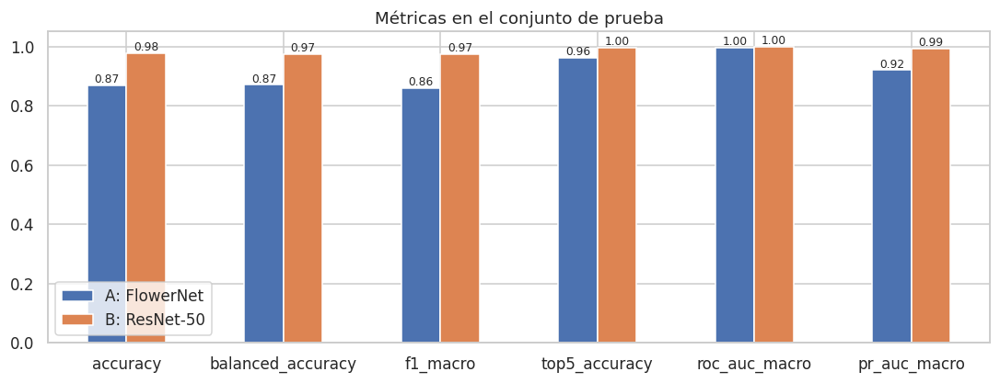

In [26]:
best_name = max(results, key=lambda n: results[n]["val_f1_macro"])
best_model = MODELS[best_name][0]
probs_test, y_test = preds[best_name]["test"]
pred_test = probs_test.argmax(1)
print(f"Mejor modelo: {best_name}")
print(f"Test: accuracy {results[best_name]['test_accuracy']:.3f} | F1 macro {results[best_name]['test_f1_macro']:.3f} "
      f"| top-5 {results[best_name]['test_top5_accuracy']:.3f}")

metric_names = ["accuracy", "balanced_accuracy", "f1_macro", "top5_accuracy", "roc_auc_macro", "pr_auc_macro"]
plot_df = pd.DataFrame({n: [results[n][f"test_{k}"] for k in metric_names] for n in results}, index=metric_names)
ax = plot_df.plot.bar(figsize=(12, 4), rot=0, ylim=(0, 1.05))
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_title("Métricas en el conjunto de prueba"); plt.show()

### 9.2 Rendimiento por clase
¿Qué especies son más difíciles? ¿El desbalance afecta el rendimiento? Comparamos el F1 de cada clase con el número de imágenes de entrenamiento que tenía.

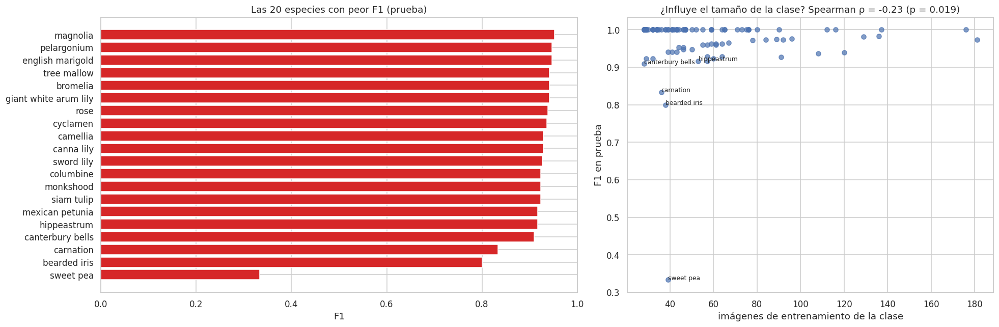

Clases con F1 = 1.0: 66 de 102


,precision,recall,f1-score,support,train_images
sweet pea,0.500,0.250,0.333,8.0,39
bearded iris,0.857,0.750,0.800,8.0,38
carnation,1.000,0.714,0.833,7.0,36
canterbury bells,1.000,0.833,0.909,6.0,28
hippeastrum,0.846,1.000,0.917,11.0,53
mexican petunia,1.000,0.846,0.917,13.0,57
siam tulip,0.857,1.000,0.923,6.0,29
monkshood,1.000,0.857,0.923,7.0,32
columbine,0.923,0.923,0.923,13.0,60
sword lily,0.864,1.000,0.927,19.0,91


In [27]:
from scipy.stats import spearmanr

report = classification_report(y_test, pred_test, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.iloc[:NUM_CLASSES]
per_class["train_images"] = class_counts
per_class = per_class.sort_values("f1-score")

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.3, 1]})
worst = per_class.head(20)
axes[0].barh(worst.index, worst["f1-score"], color="#d62728")
axes[0].set_xlabel("F1"); axes[0].set_title("Las 20 especies con peor F1 (prueba)"); axes[0].set_xlim(0, 1)
rho, pval = spearmanr(per_class["train_images"], per_class["f1-score"])
axes[1].scatter(per_class["train_images"], per_class["f1-score"], alpha=0.7)
for n, r in per_class.head(5).iterrows():
    axes[1].annotate(n, (r["train_images"], r["f1-score"]), fontsize=8)
axes[1].set_xlabel("imágenes de entrenamiento de la clase"); axes[1].set_ylabel("F1 en prueba")
axes[1].set_title(f"¿Influye el tamaño de la clase? Spearman ρ = {rho:.2f} (p = {pval:.3f})")
plt.tight_layout(); plt.show()
print(f"Clases con F1 = 1.0: {(per_class['f1-score'] == 1).sum()} de {NUM_CLASSES}")
display(per_class.head(10)[["precision", "recall", "f1-score", "support", "train_images"]].round(3))

### 9.3 Matriz de confusión y pares de especies más confundidos
Con 102 clases la matriz completa se ve como un mapa de calor: la diagonal son los aciertos y los puntos fuera de ella son confusiones. Después listamos los pares de especies que más se confunden y mostramos ejemplos.

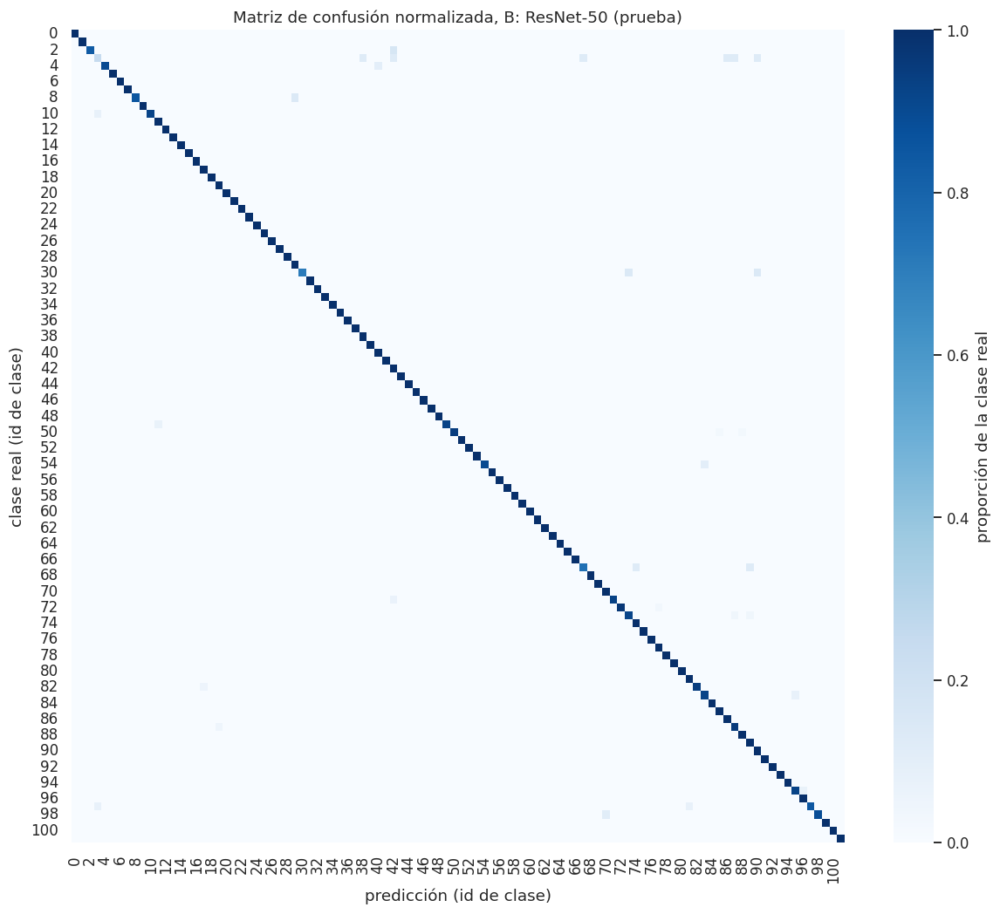

,real,predicha,errores,% de la clase real
0,canterbury bells,sword lily,1,16.7%
1,sweet pea,siam tulip,1,12.5%
2,sweet pea,sword lily,1,12.5%
3,sweet pea,bearded iris,1,12.5%
4,sweet pea,magnolia,1,12.5%
5,sweet pea,cyclamen,1,12.5%
6,sweet pea,hippeastrum,1,12.5%
7,english marigold,barbeton daisy,1,10.0%
8,monkshood,sweet william,1,14.3%
9,snapdragon,sweet pea,1,7.7%


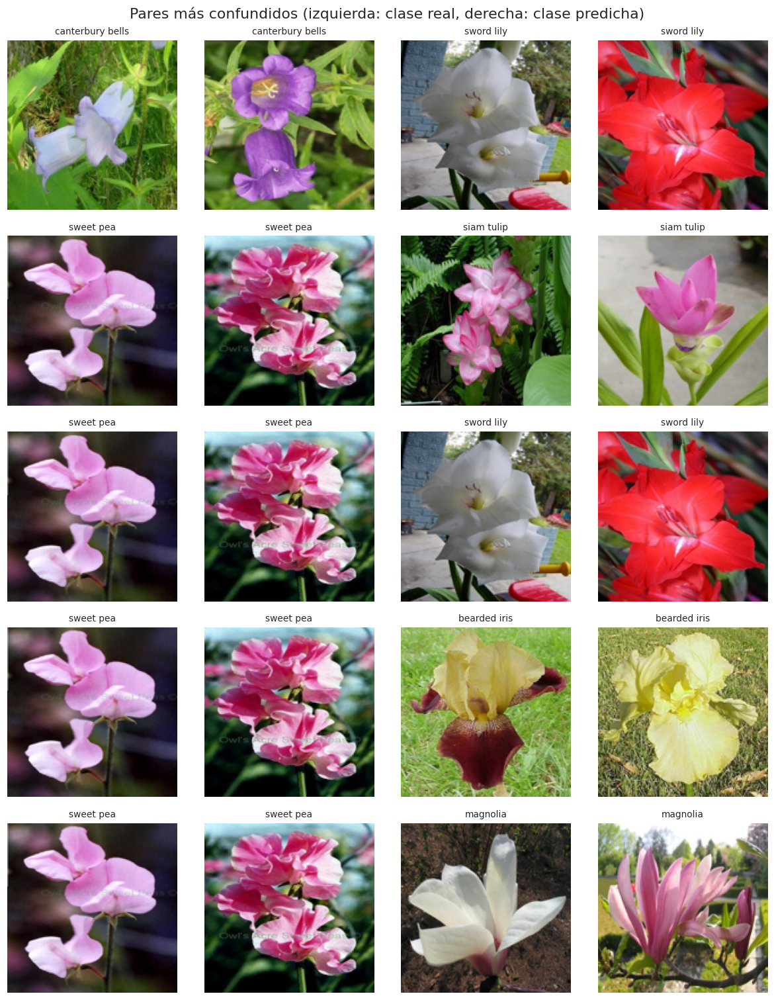

In [28]:
cm = confusion_matrix(y_test, pred_test, labels=list(range(NUM_CLASSES)))
cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm_norm, cmap="Blues", ax=ax, cbar_kws={"label": "proporción de la clase real"}, vmin=0, vmax=1)
ax.set_xlabel("predicción (id de clase)"); ax.set_ylabel("clase real (id de clase)")
ax.set_title(f"Matriz de confusión normalizada, {best_name} (prueba)"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(i, j, off[i, j]) for i, j in zip(*np.nonzero(off))]
pairs = sorted(pairs, key=lambda t: -t[2])[:15]
conf_df = pd.DataFrame([{"real": CLASS_NAMES[i], "predicha": CLASS_NAMES[j], "errores": c,
                         "% de la clase real": c / cm[i].sum()} for i, j, c in pairs])
display(conf_df.style.format({"% de la clase real": "{:.1%}"}))

top_pairs = pairs[:min(5, len(pairs))]
if top_pairs:
    fig, axes = plt.subplots(len(top_pairs), 4, figsize=(11, 2.8 * len(top_pairs)), squeeze=False)
    for row, (i, j, c) in zip(axes, top_pairs):
        a = train_df[train_df.label == i].sample(2, random_state=SEED, replace=True)
        b = train_df[train_df.label == j].sample(2, random_state=SEED, replace=True)
        for ax, f, t in zip(row, list(a.filename) + list(b.filename), [CLASS_NAMES[i]] * 2 + [CLASS_NAMES[j]] * 2):
            ax.imshow(load_rgb(f).resize((150, 150))); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.suptitle("Pares más confundidos (izquierda: clase real, derecha: clase predicha)"); plt.tight_layout(); plt.show()

### 9.4 Curvas ROC y Precision-Recall
Mostramos la curva **micro-promedio** de ambos modelos (todas las clases juntas) y las curvas de las 5 especies con peor F1 del mejor modelo.

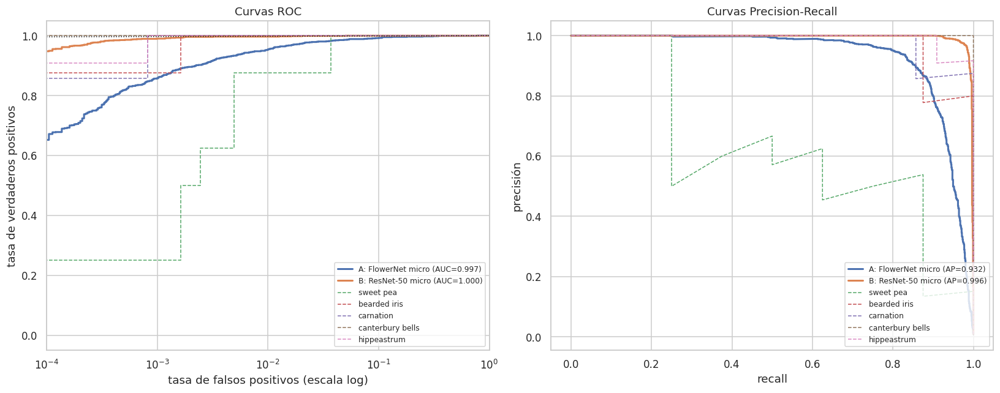

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name in MODELS:
    p, yy = preds[name]["test"]
    yb = label_binarize(yy, classes=range(NUM_CLASSES))
    fpr, tpr, _ = roc_curve(yb.ravel(), p.ravel())
    prec, rec, _ = precision_recall_curve(yb.ravel(), p.ravel())
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} micro (AUC={roc_auc_score(yb.ravel(), p.ravel()):.3f})")
    axes[1].plot(rec, prec, lw=2, label=f"{name} micro (AP={average_precision_score(yb.ravel(), p.ravel()):.3f})")

yb = label_binarize(y_test, classes=range(NUM_CLASSES))
for cname in per_class.index[:5]:
    c = CLASS_NAMES.index(cname)
    if yb[:, c].sum() == 0: continue
    fpr, tpr, _ = roc_curve(yb[:, c], probs_test[:, c])
    prec, rec, _ = precision_recall_curve(yb[:, c], probs_test[:, c])
    axes[0].plot(fpr, tpr, lw=1, ls="--", label=f"{cname}")
    axes[1].plot(rec, prec, lw=1, ls="--", label=f"{cname}")
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_xscale("log"); axes[0].set_xlim(1e-4, 1)
axes[0].set_xlabel("tasa de falsos positivos (escala log)"); axes[0].set_ylabel("tasa de verdaderos positivos")
axes[0].set_title("Curvas ROC"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precisión")
axes[1].set_title("Curvas Precision-Recall")
for ax in axes: ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 9.5 Calibración: ¿podemos confiar en la probabilidad que da el modelo?
En una aplicación real queremos decir "no estoy seguro" cuando la confianza es baja. Para eso, la probabilidad debe estar **calibrada**: si el modelo dice 80 %, debería acertar ~80 % de las veces. Medimos el **ECE** (Expected Calibration Error; menor es mejor).

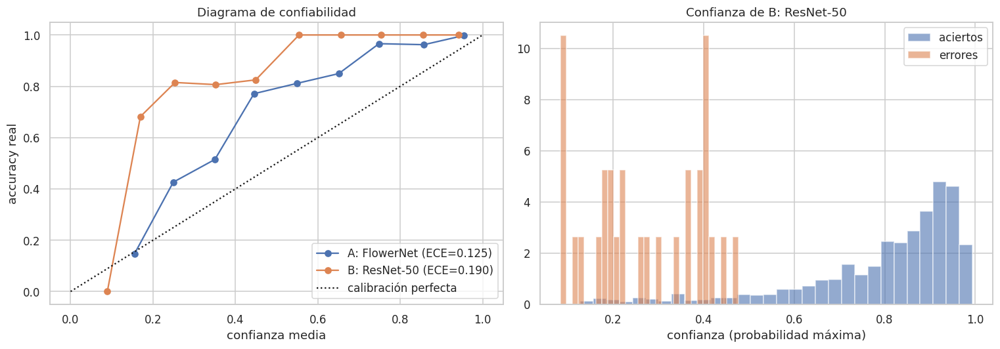

Umbral 0.5: responde en 89.9% de los casos con accuracy 1.000
Umbral 0.7: responde en 77.3% de los casos con accuracy 1.000
Umbral 0.9: responde en 34.9% de los casos con accuracy 1.000


In [30]:
def reliability(probs, y, n_bins=10):
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    ids = np.clip(np.digitize(conf, bins) - 1, 0, n_bins - 1)
    acc_b = np.array([correct[ids == b].mean() if (ids == b).any() else np.nan for b in range(n_bins)])
    conf_b = np.array([conf[ids == b].mean() if (ids == b).any() else np.nan for b in range(n_bins)])
    cnt_b = np.array([(ids == b).sum() for b in range(n_bins)])
    ece = np.nansum(cnt_b / len(y) * np.abs(acc_b - conf_b))
    return conf_b, acc_b, ece

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in MODELS:
    p, yy = preds[name]["test"]
    cb, ab, ece = reliability(p, yy)
    axes[0].plot(cb, ab, "o-", label=f"{name} (ECE={ece:.3f})")
axes[0].plot([0, 1], [0, 1], "k:", label="calibración perfecta")
axes[0].set_xlabel("confianza media"); axes[0].set_ylabel("accuracy real"); axes[0].set_title("Diagrama de confiabilidad")
axes[0].legend()
conf = probs_test.max(1)
axes[1].hist(conf[pred_test == y_test], bins=30, alpha=0.6, label="aciertos", density=True)
axes[1].hist(conf[pred_test != y_test], bins=30, alpha=0.6, label="errores", density=True)
axes[1].set_xlabel("confianza (probabilidad máxima)"); axes[1].set_title(f"Confianza de {best_name}"); axes[1].legend()
plt.tight_layout(); plt.show()

for thr in [0.5, 0.7, 0.9]:
    keep = conf >= thr
    if not keep.any():
        print(f"Umbral {thr:.1f}: ninguna predicción supera este umbral"); continue
    print(f"Umbral {thr:.1f}: responde en {keep.mean():.1%} de los casos con accuracy {(pred_test[keep] == y_test[keep]).mean():.3f}")

#### 9.5.1 Corrección con *temperature scaling*
En la corrida 1 los dos modelos salieron **subconfiados**: aciertan más de lo que dice su probabilidad (la curva queda por encima de la diagonal). Es un efecto conocido del *label smoothing*. El problema práctico es que, con un umbral de 0,5, la app diría "no estoy seguro" en ~10 % de fotos que en realidad clasifica bien.

**Temperature scaling** (Guo et al., 2017) es la corrección estándar: se divide la salida del modelo entre una temperatura *T* antes del softmax. *T* se ajusta en el conjunto de **validación** (minimizando el log-loss) y se evalúa en **prueba**. Con *T* < 1 las probabilidades se vuelven más seguras. **No cambia la predicción ni la accuracy**, solo la confianza.

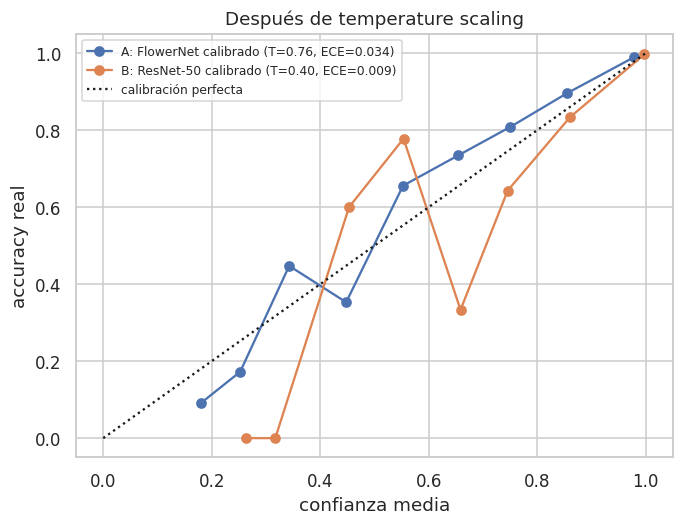

,T,ECE antes,ECE después,log-loss antes,log-loss después,accuracy (igual)
A: FlowerNet,0.760,0.125,0.034,0.614,0.518,0.869
B: ResNet-50,0.400,0.190,0.009,0.311,0.079,0.976


Umbrales con B: ResNet-50 calibrado:
  Umbral 0.5: responde en 99.3% de los casos con accuracy 0.981
  Umbral 0.7: responde en 97.6% de los casos con accuracy 0.989
  Umbral 0.9: responde en 94.5% de los casos con accuracy 0.997


In [31]:
from scipy.special import softmax

def apply_temperature(probs, T):
    return softmax(np.log(np.clip(probs, 1e-12, 1)) / T, axis=1)

def fit_temperature(probs, y, grid=np.linspace(0.05, 3.0, 296)):
    losses = [log_loss(y, apply_temperature(probs, T), labels=list(range(NUM_CLASSES))) for T in grid]
    return float(grid[int(np.argmin(losses))])

TEMPERATURE, cal_rows = {}, {}
fig, ax = plt.subplots(figsize=(7, 5))
for name in MODELS:
    pv, yv = preds[name]["val"]
    pt, yt = preds[name]["test"]
    T = fit_temperature(pv, yv)
    TEMPERATURE[name] = T
    pt_cal = apply_temperature(pt, T)
    _, _, ece_before = reliability(pt, yt)
    cb, ab, ece_after = reliability(pt_cal, yt)
    ax.plot(cb, ab, "o-", label=f"{name} calibrado (T={T:.2f}, ECE={ece_after:.3f})")
    cal_rows[name] = {"T": T, "ECE antes": ece_before, "ECE después": ece_after,
                      "log-loss antes": log_loss(yt, np.clip(pt, 1e-7, 1), labels=list(range(NUM_CLASSES))),
                      "log-loss después": log_loss(yt, np.clip(pt_cal, 1e-7, 1), labels=list(range(NUM_CLASSES))),
                      "accuracy (igual)": accuracy_score(yt, pt_cal.argmax(1))}
ax.plot([0, 1], [0, 1], "k:", label="calibración perfecta")
ax.set_xlabel("confianza media"); ax.set_ylabel("accuracy real"); ax.set_title("Después de temperature scaling")
ax.legend(fontsize=8); plt.show()
display(pd.DataFrame(cal_rows).T.style.format("{:.3f}"))

probs_test_cal = apply_temperature(probs_test, TEMPERATURE[best_name])
conf_cal = probs_test_cal.max(1)
print(f"Umbrales con {best_name} calibrado:")
for thr in [0.5, 0.7, 0.9]:
    keep = conf_cal >= thr
    if keep.any():
        print(f"  Umbral {thr:.1f}: responde en {keep.mean():.1%} de los casos con accuracy {(pred_test[keep] == y_test[keep]).mean():.3f}")

### 9.6 Galería de errores
Los errores con **mayor confianza** son los más preocupantes: el modelo se equivoca y está seguro. Revisarlos ayuda a encontrar etiquetas mal puestas, fotos atípicas o especies realmente indistinguibles.

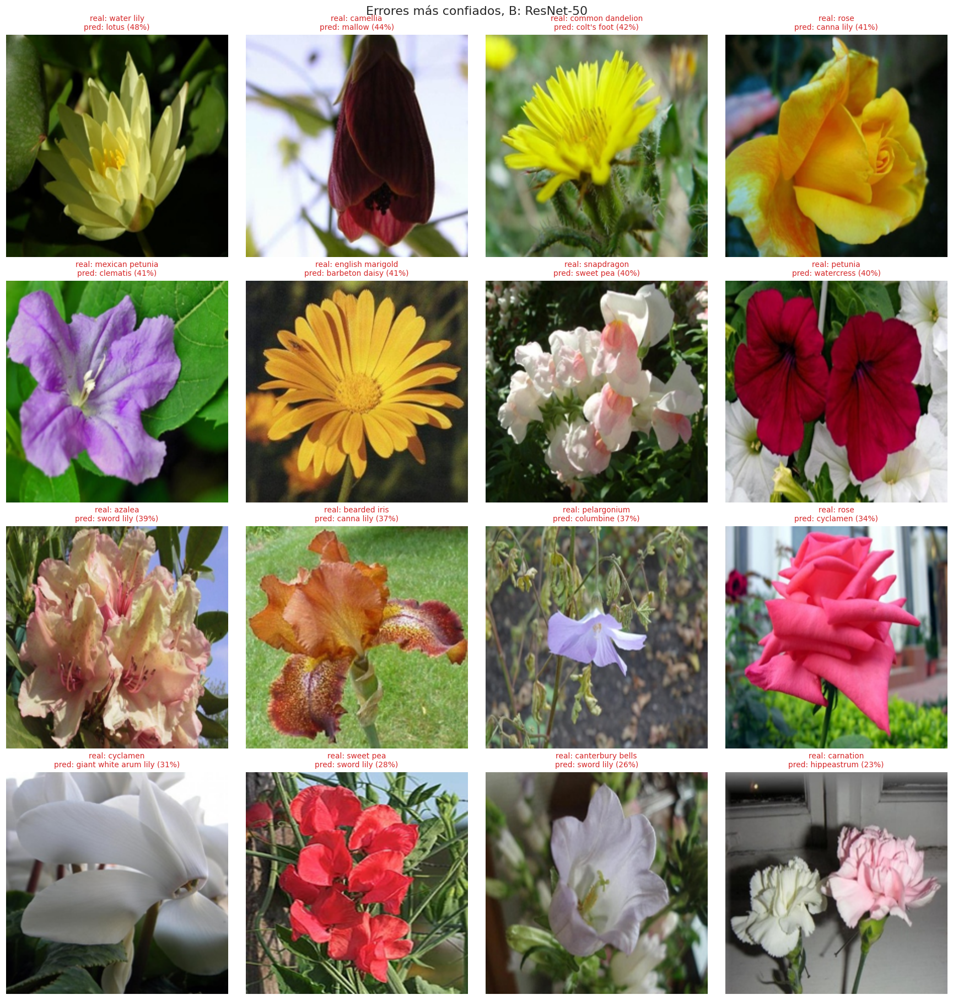

Total de errores en prueba: 29 de 1228


In [32]:
wrong = np.where(pred_test != y_test)[0]
wrong = wrong[np.argsort(-probs_test[wrong].max(1))][:16]
if len(wrong):
    cols = 4; rows = math.ceil(len(wrong) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4.2 * rows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(load_rgb(test_df.loc[i, "filename"]).resize((220, 220)))
        ax.set_title(f"real: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[pred_test[i]]} ({probs_test[i].max():.0%})",
                     fontsize=9, color="#d62728")
    plt.suptitle(f"Errores más confiados, {best_name}"); plt.tight_layout(); plt.show()
print(f"Total de errores en prueba: {(pred_test != y_test).sum()} de {len(y_test)}")

**Análisis de errores (corrida 1, Modelo B: 18 errores de 1.228):**
- **Se concentran en una especie:** *sweet pea* (guisante de olor) tiene 6 de los 18 errores. Solo acertó 2 de 8 fotos y se confundió con *cyclamen*, *siam tulip*, *columbine*, *magnolia* y *canna lily*. Sus fotos varían mucho de color (rosado, rojo, morado, fucsia), y sus pétalos ondulados se parecen a los de otras especies. Además es una de las clases con menos datos (39 imágenes de entrenamiento).
- **Formas parecidas:** los demás errores suelen ser entre especies con la misma forma general: flores en trompeta (*thorn apple* → *morning glory*), lirios con pétalos curvos (*tiger lily* → *peruvian lily*) o rosas de pétalos sueltos (*rose* → *cyclamen*, *rose* → *frangipani*).
- **Fotos atípicas:** hay errores en fotos poco representativas del dataset, por ejemplo un clavel (*carnation*) sostenido en la mano sobre una mesa, o una foto donde aparecen varias flores pequeñas.
- **Posible error de etiquetado:** una imagen etiquetada como *camellia* parece más una flor de la familia de las malváceas (como un *Abutilon*), que es justamente lo que predijo el modelo (*mallow*). No lo podemos confirmar sin un experto en botánica, pero muestra que el dataset también puede tener ruido en las etiquetas.
- **Los errores son de baja confianza:** el error más "seguro" tuvo 43 % de probabilidad y la mayoría estuvieron por debajo del 25 %. Un umbral de confianza filtraría casi todos los errores, lo cual es muy favorable para una aplicación real.

### 9.7 Mejora basada en hallazgos: test-time augmentation (TTA)
Como el modelo falla en algunas fotos por la orientación o el encuadre, probamos promediar la predicción de la imagen original y la de su reflejo horizontal. No requiere reentrenar.

In [33]:
tta_rows = {}
for name, (m, _) in MODELS.items():
    p_tta, yy = predict(m, test_loader, tta=True)
    base = compute_metrics(*preds[name]["test"])
    tta = compute_metrics(p_tta, yy)
    tta_rows[name] = {"accuracy sin TTA": base["accuracy"], "accuracy con TTA": tta["accuracy"],
                      "F1 macro sin TTA": base["f1_macro"], "F1 macro con TTA": tta["f1_macro"]}
display(pd.DataFrame(tta_rows).T.style.format("{:.3f}"))

,accuracy sin TTA,accuracy con TTA,F1 macro sin TTA,F1 macro con TTA
A: FlowerNet,0.869,0.868,0.860,0.859
B: ResNet-50,0.976,0.980,0.974,0.977


## 10. Explicabilidad, robustez y pruebas con fotos reales

### 10.1 Grad-CAM: ¿en qué se fija el modelo?
**Grad-CAM** (Selvaraju et al., 2017) usa los gradientes de la clase predicha respecto a la última capa convolucional para resaltar las regiones de la imagen que más influyeron en la decisión. Así verificamos que el modelo mira la **flor** y no el fondo (hojas, cielo, macetas). Esto es clave para la transparencia y la explicabilidad del sistema.

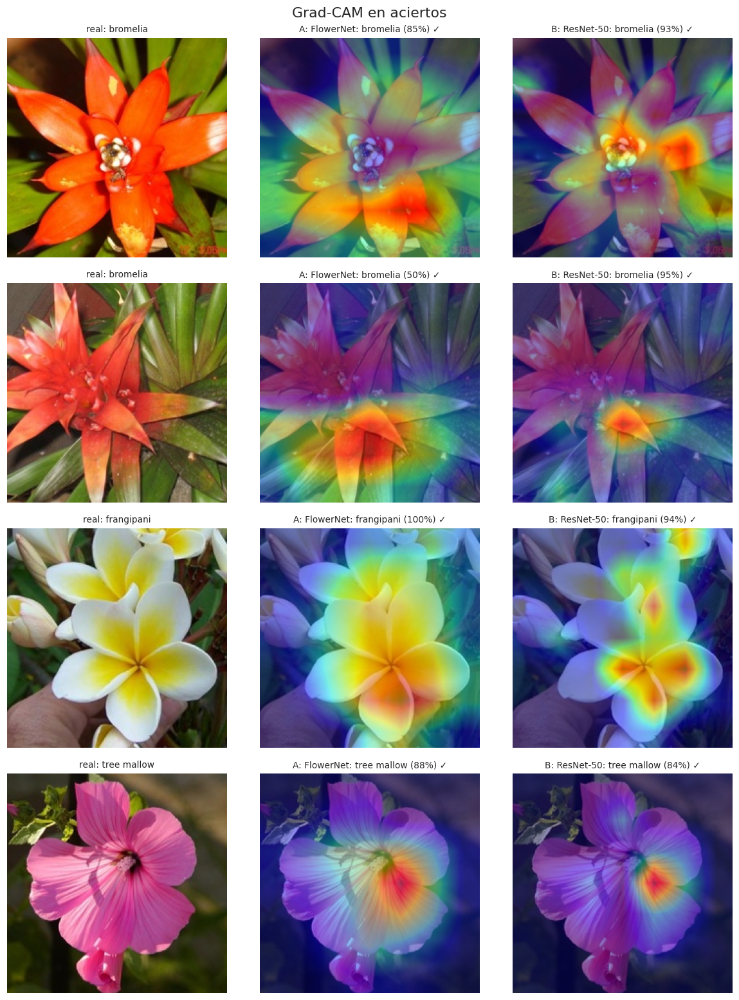

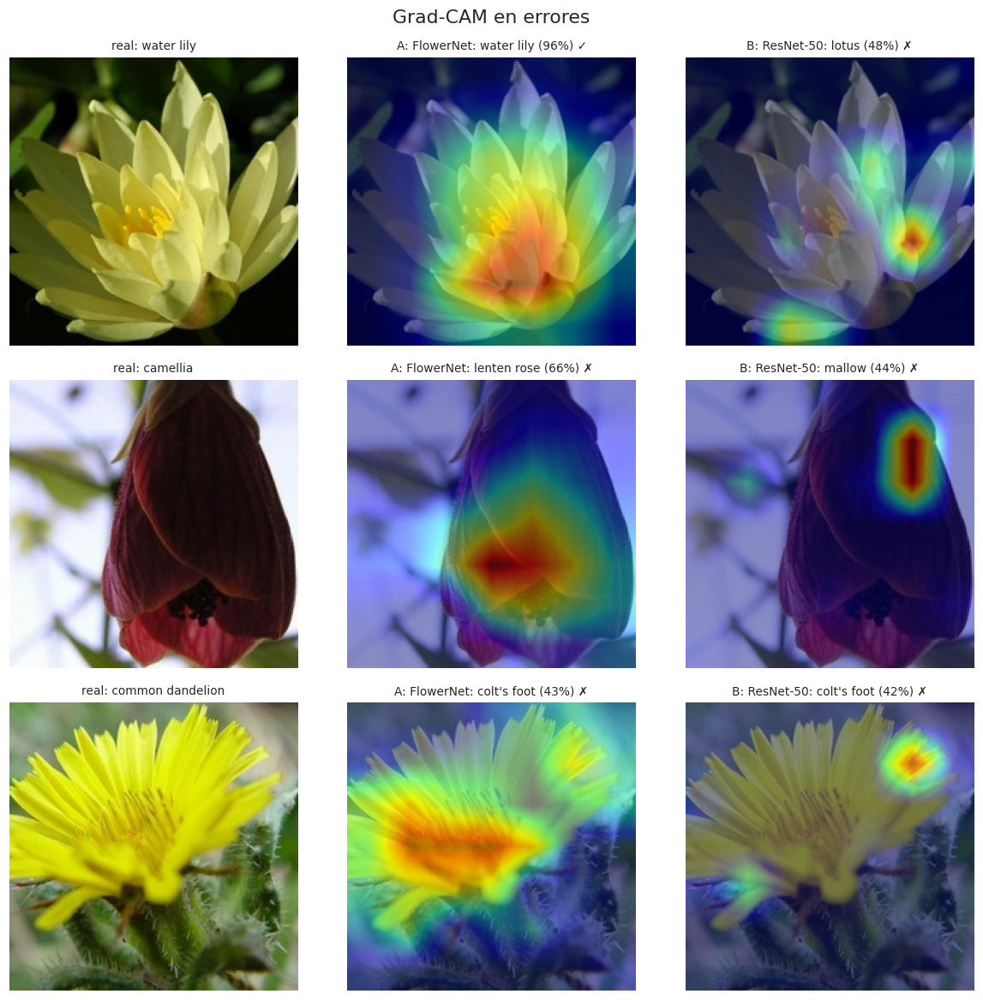

In [34]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out.detach()
        if out.requires_grad:          # solo cuando calculamos Grad-CAM (no en predicciones normales)
            out.register_hook(lambda g: setattr(self, "grads", g.detach()))
    def __call__(self, x, class_idx=None):
        self.model.eval()
        with torch.enable_grad():
            out = self.model(x)
            idx = out.argmax(1).item() if class_idx is None else class_idx
            self.model.zero_grad(set_to_none=True)
            out[0, idx].backward()
        w = self.grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), idx, out.softmax(1)[0, idx].item()

cams = {NAME_A: GradCAM(model_a, model_a.stage4[-1]),
        NAME_B: GradCAM(model_b, model_b.layer4[-1])}

def show_gradcam(indices, frame, title):
    fig, axes = plt.subplots(len(indices), 3, figsize=(11, 3.6 * len(indices)), squeeze=False)
    for row, i in zip(axes, indices):
        x = eval_tf(load_rgb(frame.loc[i, "filename"])).unsqueeze(0).to(device)
        row[0].imshow(denorm(x[0])); row[0].set_title(f"real: {frame.loc[i, 'class_name']}", fontsize=9)
        for ax, (name, cam) in zip(row[1:], cams.items()):
            heat, idx, p = cam(x)
            ax.imshow(denorm(x[0])); ax.imshow(heat, cmap="jet", alpha=0.45)
            ok = "✓" if idx == frame.loc[i, "label"] else "✗"
            ax.set_title(f"{name}: {CLASS_NAMES[idx]} ({p:.0%}) {ok}", fontsize=9)
        for ax in row: ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
correct_idx = rng.choice(np.where(pred_test == y_test)[0], size=min(4, (pred_test == y_test).sum()), replace=False)
show_gradcam(correct_idx, test_df, "Grad-CAM en aciertos")
if len(wrong):
    show_gradcam(wrong[:3], test_df, "Grad-CAM en errores")

### 10.2 Robustez ante condiciones del mundo real
Las fotos de usuarios reales no son como las del dataset: hay desenfoque, poca luz, compresión de WhatsApp, baja resolución... Simulamos estas condiciones sobre el conjunto de prueba para medir cuánto cae el rendimiento.

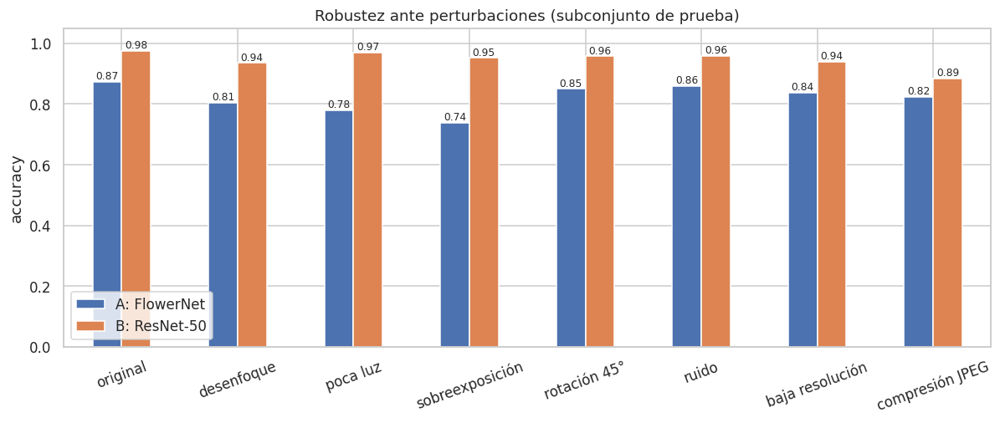

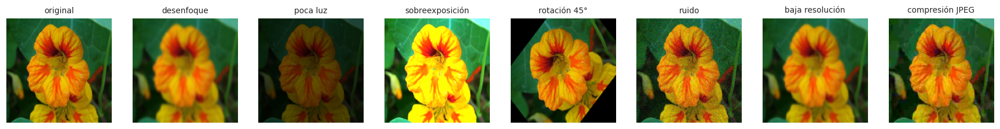

In [35]:
import io

def add_noise(im, sigma=25):
    a = np.asarray(im, dtype=np.float32) + np.random.default_rng(0).normal(0, sigma, (im.size[1], im.size[0], 3))
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

def jpeg(im, q=10):
    buf = io.BytesIO(); im.save(buf, "JPEG", quality=q); buf.seek(0)
    return Image.open(buf).convert("RGB")

def low_res(im, f=4):
    w, h = im.size
    return im.resize((max(1, w // f), max(1, h // f)), Image.BILINEAR).resize((w, h), Image.BILINEAR)

CORRUPTIONS = {
    "original": None,
    "desenfoque": lambda im: im.filter(ImageFilter.GaussianBlur(3)),
    "poca luz": lambda im: ImageEnhance.Brightness(im).enhance(0.4),
    "sobreexposición": lambda im: ImageEnhance.Brightness(im).enhance(1.8),
    "rotación 45°": lambda im: im.rotate(45),
    "ruido": add_noise,
    "baja resolución": low_res,
    "compresión JPEG": jpeg,
}
robust_df = test_df.sample(min(1000, len(test_df)), random_state=SEED).reset_index(drop=True)
rob = {}
for cname, fn in CORRUPTIONS.items():
    dl = DataLoader(FlowerDataset(robust_df, eval_tf, pil_corruption=fn), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    rob[cname] = {}
    for name, (m, _) in MODELS.items():
        p, yy = predict(m, dl)
        rob[cname][name] = accuracy_score(yy, p.argmax(1))
rob_df = pd.DataFrame(rob).T
ax = rob_df.plot.bar(figsize=(13, 4.5), rot=20, ylim=(0, 1.05))
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_ylabel("accuracy"); ax.set_title("Robustez ante perturbaciones (subconjunto de prueba)"); plt.show()

ex = load_rgb(robust_df.loc[0, "filename"])
fig, axes = plt.subplots(1, len(CORRUPTIONS), figsize=(20, 3))
for ax, (cname, fn) in zip(axes, CORRUPTIONS.items()):
    ax.imshow((fn(ex) if fn else ex).resize((160, 160))); ax.set_title(cname, fontsize=9); ax.axis("off")
plt.show()

**Observaciones:** en la corrida 1 (sin aumento de desenfoque y ruido), el Modelo B resistió bien la poca luz, la sobreexposición y la rotación (≥ 95 %), pero cayó con **desenfoque (59 %)**, **baja resolución (66 %)**, **ruido (72 %)** y **compresión JPEG (76 %)**. El Modelo A colapsó con desenfoque (12 %) y ruido (9 %). Esto es lo que más preocupa en una app real, donde las fotos suelen ser movidas o de cámaras de gama baja. Por eso agregamos esas perturbaciones al aumento de datos (sección 5.3) y comparamos el resultado en la sección 11.3.

### 10.3 Pruebas con fotos del mundo real
Tomen fotos de flores con su celular (jardín, floristería, parque) y cópienlas a la carpeta `fotos_reales` (se crea junto al notebook; en Colab es `/content/fotos_reales`). En Colab también pueden poner `UPLOAD_PHOTOS = True` para subirlas desde el navegador.

**Importante:** el modelo solo conoce 102 especies comunes en el Reino Unido. Si le muestran una flor que no está en el catálogo (o algo que no es una flor), igual va a responder alguna de las 102. Por eso usamos un **umbral de confianza**: por debajo de él, la app debería responder "no estoy seguro". Esta limitación es un buen punto para la discusión ética y práctica.

In [36]:
UPLOAD_PHOTOS = False
REAL_DIR = BASE_DIR / "fotos_reales"
CONF_THRESHOLD = 0.5
REAL_DIR.mkdir(parents=True, exist_ok=True)

if UPLOAD_PHOTOS and EN_COLAB:
    from google.colab import files
    for fname, data in files.upload().items():
        (REAL_DIR / fname).write_bytes(data)

def predict_photo(img, model=best_model, k=5, T=TEMPERATURE[best_name]):
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        p = (model(x).float() / T).softmax(1)[0].cpu().numpy()   # probabilidades calibradas
    top = np.argsort(-p)[:k]
    return x, [(CLASS_NAMES[i], p[i]) for i in top]

photos = sorted([p for p in REAL_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}])
print(f"Fotos encontradas: {len(photos)}")
best_cam = cams[best_name]
for path in photos:
    img = Image.open(path)
    x, top = predict_photo(img)
    heat, _, _ = best_cam(x)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(img); axes[0].set_title(path.name); axes[0].axis("off")
    axes[1].imshow(denorm(x[0])); axes[1].imshow(heat, cmap="jet", alpha=0.45); axes[1].axis("off")
    axes[1].set_title("Grad-CAM")
    names, ps = zip(*top)
    axes[2].barh(names[::-1], ps[::-1], color=["#2ca02c" if ps[0] >= CONF_THRESHOLD else "#ff7f0e"] * len(ps))
    axes[2].set_xlim(0, 1)
    verdict = names[0] if ps[0] >= CONF_THRESHOLD else "No estoy seguro: posible especie fuera del catálogo"
    axes[2].set_title(verdict, fontsize=10)
    plt.tight_layout(); plt.show()

Fotos encontradas: 0


## 11. Consumo energético, exportación y conclusiones

### 11.1 Estimación de consumo energético y huella de carbono
Estimación aproximada: tiempo de entrenamiento × potencia de la GPU. Es un **límite inferior**, porque no incluye CPU, memoria ni refrigeración del centro de datos. Para la huella de carbono necesitan el **factor de emisión** (kg CO₂e por kWh) de la red eléctrica donde corre el cómputo:
- el entrenamiento en Colab corre en centros de datos de Google (otra región);
- si el sistema se despliega en Colombia, usen el factor de la red colombiana publicado por la UPME o XM.

Pongan el valor con su fuente en `FACTOR_EMISION`.

In [37]:
POTENCIA_GPU_W = 70 if device == "cuda" else 45   # W: T4 de Colab = 70; en CPU/portátil pongan la potencia de su equipo
FACTOR_EMISION = None        # kg CO2e / kWh, completar con un valor y su fuente

energy = {}
for name, (m, h) in MODELS.items():
    kwh = h["train_time_s"] / 3600 * POTENCIA_GPU_W / 1000
    energy[name] = {"tiempo (min)": h["train_time_s"] / 60, "energía (kWh)": kwh}
    if FACTOR_EMISION is not None:
        energy[name]["CO2e (g)"] = kwh * FACTOR_EMISION * 1000
display(pd.DataFrame(energy).T.style.format("{:.4f}"))

,tiempo (min),energía (kWh)
A: FlowerNet,46.5622,0.0543
B: ResNet-50,17.0683,0.0199


### 11.2 Exportar el mejor modelo para producción
Guardamos los pesos, los nombres de las clases y la configuración de preprocesamiento. Esto es lo que necesitaría una API (por ejemplo con FastAPI) o una app móvil para usar el modelo. También intentamos exportar a TorchScript, un formato que se puede cargar sin el código de Python de la arquitectura.

In [38]:
EXPORT_DIR = Path(CHECKPOINT_DIR) / "export"
EXPORT_DIR.mkdir(exist_ok=True)
tag = "flowernet" if best_name == NAME_A else TL_ARCH
torch.save(best_model.state_dict(), EXPORT_DIR / f"{tag}_flowers102.pt")
with open(EXPORT_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump({"model": tag, "class_names": CLASS_NAMES, "img_size": IMG_SIZE, "resize": RESIZE_SHORT_SIDE,
               "mean": IMAGENET_MEAN, "std": IMAGENET_STD, "conf_threshold": CONF_THRESHOLD,
               "temperature": TEMPERATURE[best_name],
               "test_metrics": {k.replace("test_", ""): float(v) for k, v in results[best_name].items() if k.startswith("test_")}},
              f, indent=2, ensure_ascii=False)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # torch.jit.trace muestra un aviso de obsolescencia
try:
    cpu_model = FlowerNet() if tag == "flowernet" else build_tl_model(best_hp["dropout"], pretrained=False)
    cpu_model.load_state_dict({k: v.cpu() for k, v in best_model.state_dict().items()})
    cpu_model.eval()
    traced = torch.jit.trace(cpu_model, torch.randn(1, 3, IMG_SIZE, IMG_SIZE))
    traced.save(str(EXPORT_DIR / f"{tag}_flowers102_torchscript.pt"))
except Exception as e:
    print("TorchScript no disponible:", e)
print("Archivos exportados:", [p.name for p in EXPORT_DIR.iterdir()])

Archivos exportados: ['resnet50_flowers102.pt', 'config.json', 'resnet50_flowers102_torchscript.pt']
